# 04 – Eredmények vizualizációja és gazdasági értelmezése

A notebook célja az adattisztítás, a feltáró elemzés, a klaszterezés és
a gépi tanulási előrejelzés legfontosabb eredményeinek egységes,
közérthető és szakdolgozatban felhasználható vizuális bemutatása.

A notebook nem végez újabb modellhangolást vagy modellválasztást.
Kizárólag az előző notebookokban elmentett eredményeket használja fel.

## 4.1. Környezet és eredményfájlok betöltése

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
# ÚTVONALAK

BASE_DIR = Path.cwd()
PROCESSED = BASE_DIR / "processed"
ML_RESULTS = BASE_DIR / "results" / "machine_learning"
VIS_RESULTS = BASE_DIR / "results" / "visualization"
VIS_FIGURES = BASE_DIR / "figures" / "final_visualizations"
VIS_RESULTS.mkdir(parents=True, exist_ok=True)
VIS_FIGURES.mkdir(parents=True, exist_ok=True)

# EGYSÉGES ÁBRASTÍLUS

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 13,           
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "legend.fontsize": 13,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13
})

MODEL_COLORS = {
    "Végleges Ridge": "#0072B2",
    "Naiv – előző negyedév": "#E69F00",
    "Szezonális naiv – előző év": "#009E73"
}

def huf_axis_formatter(value, position=None):
    """Ezres tagolás szóközzel."""
    return f"{value:,.0f}".replace(",", " ")

huf_formatter = FuncFormatter(huf_axis_formatter)

print("A vizualizációs környezet létrejött.")

A vizualizációs környezet létrejött.


In [2]:
FILES = {
    "final_predictions":
        ML_RESULTS / "KSH_final_test_all_predictions.csv",

    "final_summary":
        ML_RESULTS / "KSH_final_test_summary.csv",

    "quarterly_metrics":
        ML_RESULTS / "KSH_final_test_quarterly_metrics.csv",

    "ridge_error_data":
        ML_RESULTS / "KSH_final_ridge_error_data.csv",

    "regional_errors":
        ML_RESULTS / "KSH_final_ridge_regional_errors.csv",

    "quarterly_bias":
        ML_RESULTS / "KSH_final_ridge_quarterly_bias.csv",

    "coefficient_summary":
        ML_RESULTS / "KSH_final_ridge_coefficient_summary.csv",

    "cluster_profiles":
        PROCESSED / "KSH_teruleti_profilok_klaszterekkel.csv",

    "cluster_panel":
        PROCESSED / "KSH_panel_klaszterekkel.csv"
}

missing_files = [
    str(file_path)
    for file_path in FILES.values()
    if not file_path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "A következő szükséges fájlok hiányoznak:\n- "
        + "\n- ".join(missing_files)
    )

print("Minden szükséges eredményfájl elérhető.")

Minden szükséges eredményfájl elérhető.


In [3]:
def read_csv_clean(file_path):
    """CSV betöltése és az esetleges névtelen indexoszlopok eltávolítása."""
    
    data = pd.read_csv(
        file_path,
        encoding="utf-8-sig"
    )
    
    unnamed_columns = [
        column
        for column in data.columns
        if str(column).startswith("Unnamed:")
    ]
    
    return data.drop(
        columns=unnamed_columns,
        errors="ignore"
    )


loaded_data = {
    name: read_csv_clean(file_path)
    for name, file_path in FILES.items()
}

final_predictions = loaded_data["final_predictions"]
final_summary = loaded_data["final_summary"]
quarterly_metrics = loaded_data["quarterly_metrics"]
ridge_error_data = loaded_data["ridge_error_data"]
regional_errors = loaded_data["regional_errors"]
quarterly_bias = loaded_data["quarterly_bias"]
coefficient_summary = loaded_data["coefficient_summary"]
cluster_profiles = loaded_data["cluster_profiles"]
cluster_panel = loaded_data["cluster_panel"]

# DÁTUMTÍPUSOK HELYREÁLLÍTÁSA

for data in [
    final_predictions,
    quarterly_metrics,
    ridge_error_data,
    quarterly_bias
]:
    if "Cél_Dátum" in data.columns:
        data["Cél_Dátum"] = pd.to_datetime(
            data["Cél_Dátum"]
        )

if "Dátum" in cluster_panel.columns:
    cluster_panel["Dátum"] = pd.to_datetime(
        cluster_panel["Dátum"]
    )

print("Az eredménytáblák betöltése megtörtént.")

Az eredménytáblák betöltése megtörtént.


In [4]:
required_prediction_columns = {
    "Modell",
    "Cél_Dátum",
    "Területi egység neve",
    "Valós_bér",
    "Predikció"
}

assert required_prediction_columns.issubset(
    final_predictions.columns
)

assert len(final_predictions) == 480
assert final_predictions["Modell"].nunique() == 3
assert final_predictions["Cél_Dátum"].nunique() == 8

assert (
    final_predictions
    .groupby("Modell")
    .size()
    .eq(160)
    .all()
)

assert len(quarterly_metrics) == 24
assert len(regional_errors) == 20
assert len(ridge_error_data) == 160
assert len(quarterly_bias) == 8
assert coefficient_summary["Feature"].nunique() == 34

assert cluster_profiles[
    "Területi egység neve"
].nunique() == 20

assert {
    "Klaszter",
    "Klaszter_neve"
}.issubset(cluster_profiles.columns)


data_catalog = pd.DataFrame({
    "Adathalmaz": loaded_data.keys(),
    "Sorok": [
        len(data)
        for data in loaded_data.values()
    ],
    "Oszlopok": [
        data.shape[1]
        for data in loaded_data.values()
    ]
})

display(data_catalog)

print(
    "A 4. notebook adatforrásai megfelelnek "
    "a várt szerkezetnek."
)

,Adathalmaz,Sorok,Oszlopok
0,final_predictions,480,13
1,final_summary,3,12
2,quarterly_metrics,24,5
3,ridge_error_data,160,17
4,regional_errors,20,12
5,quarterly_bias,8,11
6,coefficient_summary,34,14
7,cluster_profiles,20,18
8,cluster_panel,640,20


A 4. notebook adatforrásai megfelelnek a várt szerkezetnek.


## 4.2. A végleges modell és a benchmarkok összehasonlítása

Az első összefoglaló ábra a 2024–2025-ös, korábban érintetlen végső
tesztidőszak eredményeit mutatja be. A felső panel a valós és az
előrejelzett átlagbérek időbeli alakulását, az alsó panel pedig a
modellek negyedéves átlagos abszolút hibáját szemlélteti.

Az átlagbérek a vizsgálatban szereplő 20 területi egység egyszerű,
súlyozatlan átlagai, ezért nem értelmezhetők hivatalos országos
KSH-átlagként.

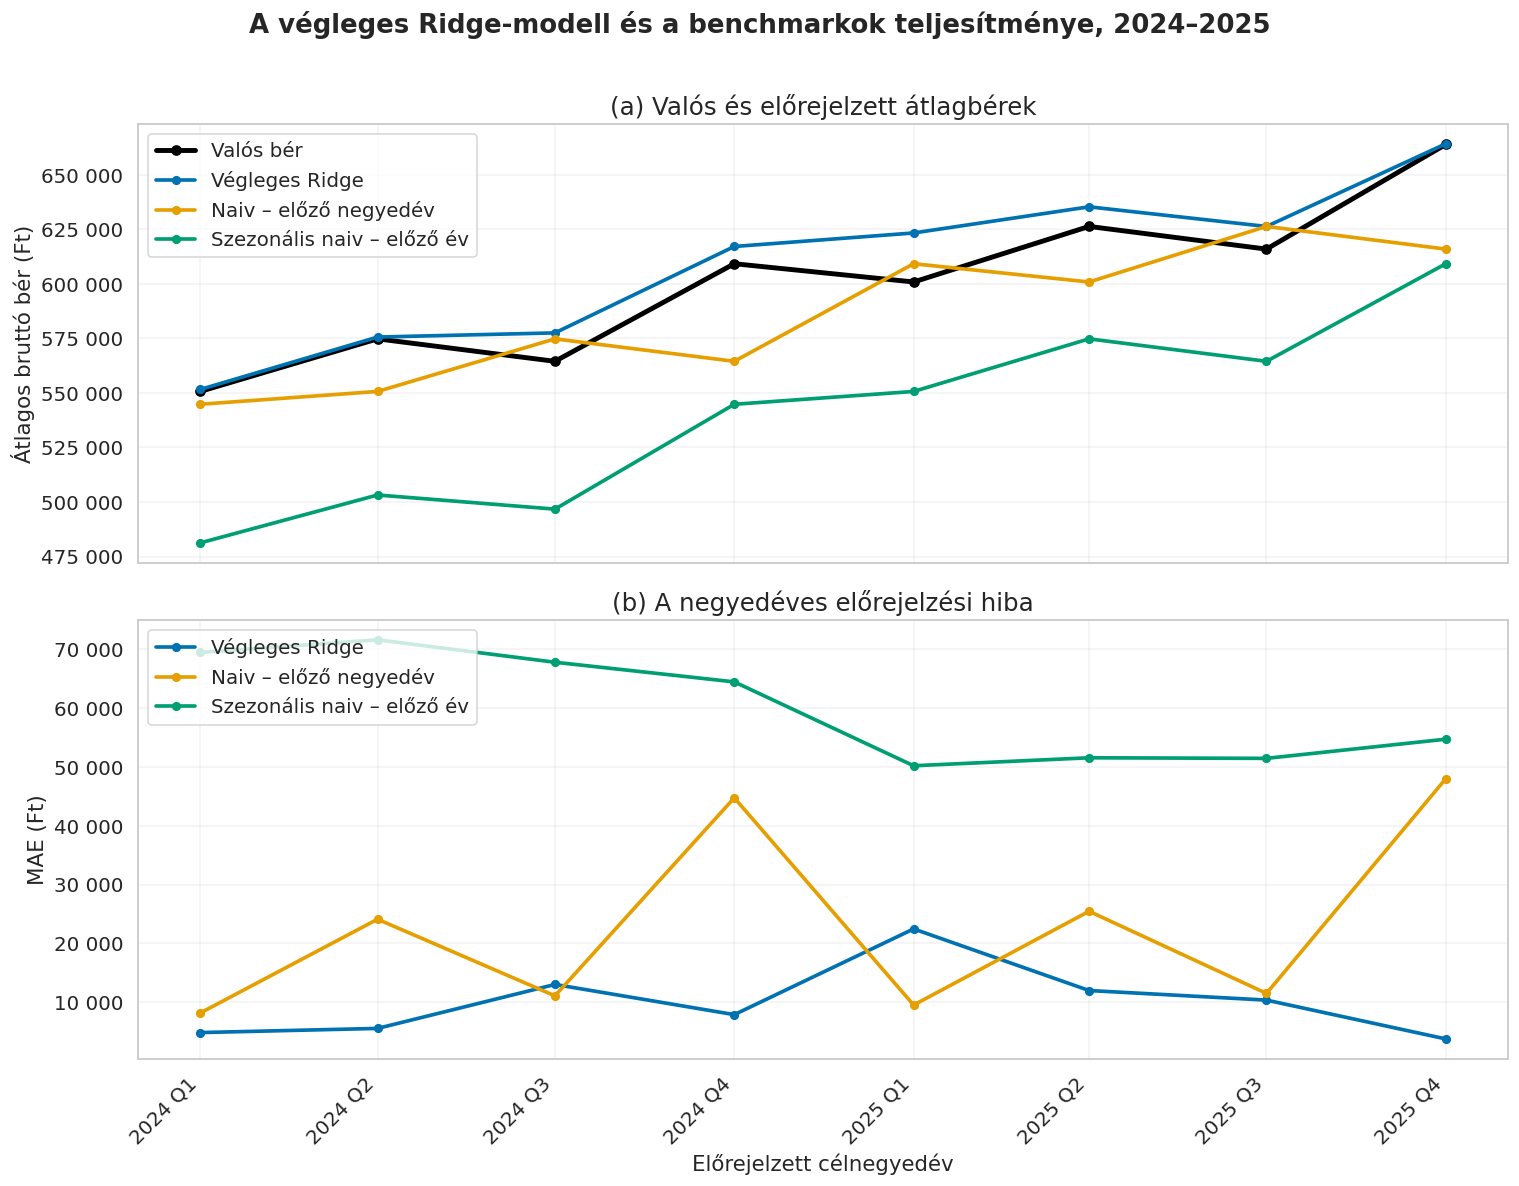

In [5]:
MODEL_ORDER = [
    "Végleges Ridge",
    "Naiv – előző negyedév",
    "Szezonális naiv – előző év"
]

assert set(MODEL_ORDER) == set(
    final_predictions["Modell"].unique()
)

# A valós értékeket csak egy modell soraiból vesszük,
# így nem számítjuk ugyanazokat többször.

actual_mean = (
    final_predictions.loc[
        final_predictions["Modell"] == "Végleges Ridge"
    ]
    .groupby("Cél_Dátum", as_index=False)
    ["Valós_bér"]
    .mean()
)

predicted_mean = (
    final_predictions
    .groupby(
        ["Modell", "Cél_Dátum"],
        as_index=False
    )
    ["Predikció"]
    .mean()
)

target_dates = sorted(
    final_predictions["Cél_Dátum"].unique()
)

quarter_labels = [
    f"{pd.Timestamp(date).year} Q{pd.Timestamp(date).quarter}"
    for date in target_dates
]


fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(14, 11),
    sharex=True
)

# (A) VALÓS ÉS ELŐREJELZETT ÁTLAGBÉREK

axes[0].plot(
    actual_mean["Cél_Dátum"],
    actual_mean["Valós_bér"],
    color="black",
    linewidth=3.2,
    marker="o",
    markersize=6,
    label="Valós bér"
)

for model_name in MODEL_ORDER:
    
    model_data = (
        predicted_mean.loc[
            predicted_mean["Modell"] == model_name
        ]
        .sort_values("Cél_Dátum")
    )
    
    axes[0].plot(
        model_data["Cél_Dátum"],
        model_data["Predikció"],
        color=MODEL_COLORS[model_name],
        linewidth=2.4,
        marker="o",
        markersize=5,
        label=model_name
    )

axes[0].set_title(
    "(a) Valós és előrejelzett átlagbérek"
)

axes[0].set_ylabel(
    "Átlagos bruttó bér (Ft)"
)

axes[0].yaxis.set_major_formatter(
    huf_formatter
)

axes[0].legend(
    loc="upper left",
    frameon=True
)

axes[0].grid(
    alpha=0.25
)

# (B) NEGYEDÉVES MAE

for model_name in MODEL_ORDER:
    
    model_metrics = (
        quarterly_metrics.loc[
            quarterly_metrics["Modell"] == model_name
        ]
        .sort_values("Cél_Dátum")
    )
    
    axes[1].plot(
        model_metrics["Cél_Dátum"],
        model_metrics["MAE"],
        color=MODEL_COLORS[model_name],
        linewidth=2.4,
        marker="o",
        markersize=5,
        label=model_name
    )

axes[1].set_title(
    "(b) A negyedéves előrejelzési hiba"
)

axes[1].set_xlabel(
    "Előrejelzett célnegyedév"
)

axes[1].set_ylabel(
    "MAE (Ft)"
)

axes[1].yaxis.set_major_formatter(
    huf_formatter
)

axes[1].set_xticks(
    target_dates
)

axes[1].set_xticklabels(
    quarter_labels,
    rotation=45,
    ha="right"
)

axes[1].legend(
    loc="upper left",
    frameon=True
)

axes[1].grid(
    alpha=0.25
)


fig.suptitle(
    "A végleges Ridge-modell és a benchmarkok teljesítménye, 2024–2025",
    fontsize=17,
    fontweight="bold"
)

fig.tight_layout(
    rect=[0, 0, 1, 0.97]
)


fig.savefig(
    VIS_FIGURES / "01_modell_osszehasonlitas_2024_2025.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    VIS_FIGURES / "01_modell_osszehasonlitas_2024_2025.pdf",
    bbox_inches="tight"
)

plt.show()

## 4.3. Az előrejelzési teljesítmény összehasonlítása klaszterenként

Ebben a részben a feltáró elemzés során kialakított területi
klasztereket összekapcsoljuk a végleges Ridge-modell 2024–2025-ös
előrejelzési hibáival.

A vizsgálat célja annak megállapítása, hogy a modell hasonló
pontossággal működik-e az eltérő gazdasági helyzetű területi
csoportokban.

A klaszterenkénti összehasonlítás során az MAE, az RMSE, a MAPE,
az átlagos irányított hiba és a felülbecslések aránya kerül
meghatározásra.

In [6]:
# EGYEDI TERÜLET–KLASZTER KAPCSOLÓTÁBLA

cluster_lookup = (
    cluster_profiles[
        [
            "Területi egység neve",
            "Klaszter",
            "Klaszter_neve"
        ]
    ]
    .drop_duplicates()
    .sort_values("Területi egység neve")
    .reset_index(drop=True)
)

assert len(cluster_lookup) == 20

assert not cluster_lookup[
    "Területi egység neve"
].duplicated().any()

# A KLASZTEREK HOZZÁKAPCSOLÁSA A RIDGE HIBÁKHOZ

ridge_errors_clustered = (
    ridge_error_data
    .merge(
        cluster_lookup,
        on="Területi egység neve",
        how="left",
        validate="many_to_one"
    )
)

assert len(ridge_errors_clustered) == 160

assert ridge_errors_clustered[
    [
        "Klaszter",
        "Klaszter_neve"
    ]
].notna().all().all()

assert ridge_errors_clustered[
    "Klaszter"
].nunique() == 2

assert (
    ridge_errors_clustered
    .groupby("Területi egység neve")
    ["Cél_Dátum"]
    .nunique()
    .eq(8)
    .all()
)

print(
    "A klaszterbesorolások és az előrejelzési "
    "hibák összekapcsolása sikeres."
)

display(
    ridge_errors_clustered[
        [
            "Célnegyedév",
            "Területi egység neve",
            "Klaszter",
            "Klaszter_neve",
            "Valós_bér",
            "Predikció",
            "Hiba",
            "Abszolút_hiba"
        ]
    ]
    .head()
    .round(2)
)

A klaszterbesorolások és az előrejelzési hibák összekapcsolása sikeres.


,Célnegyedév,Területi egység neve,Klaszter,Klaszter_neve,Valós_bér,Predikció,Hiba,Abszolút_hiba
0,2024Q1,Baranya,2,Alacsonyabb bérszint / magasabb munkanélküliség,528655.0,523809.86,-4845.14,4845.14
1,2024Q1,Borsod-Abaúj-Zemplén,2,Alacsonyabb bérszint / magasabb munkanélküliség,496513.0,502344.13,5831.13,5831.13
2,2024Q1,Budapest,1,Magasabb bérszint / alacsonyabb munkanélküliség,756590.0,754625.76,-1964.24,1964.24
3,2024Q1,Bács-Kiskun,1,Magasabb bérszint / alacsonyabb munkanélküliség,535041.0,533416.27,-1624.73,1624.73
4,2024Q1,Békés,2,Alacsonyabb bérszint / magasabb munkanélküliség,468900.0,473602.46,4702.46,4702.46


In [7]:
cluster_error_summary = (
    ridge_errors_clustered
    .groupby(
        [
            "Klaszter",
            "Klaszter_neve"
        ],
        as_index=False
    )
    .agg(
        Területek=(
            "Területi egység neve",
            "nunique"
        ),

        Megfigyelések=(
            "Abszolút_hiba",
            "size"
        ),

        Átlagos_valós_bér_Ft=(
            "Valós_bér",
            "mean"
        ),

        Bias_Ft=(
            "Hiba",
            "mean"
        ),

        MAE_Ft=(
            "Abszolút_hiba",
            "mean"
        ),

        Átlagos_négyzetes_hiba=(
            "Hiba",
            lambda values: np.mean(
                np.square(values)
            )
        ),

        MAPE_pct=(
            "APE_%",
            "mean"
        ),

        Felülbecslések_aránya=(
            "Felülbecslés",
            "mean"
        )
    )
    .sort_values("Klaszter")
    .reset_index(drop=True)
)

cluster_error_summary[
    "RMSE_Ft"
] = np.sqrt(
    cluster_error_summary[
        "Átlagos_négyzetes_hiba"
    ]
)

cluster_error_summary[
    "Felülbecslések_aránya_pct"
] = (
    cluster_error_summary[
        "Felülbecslések_aránya"
    ]
    *
    100
)

cluster_error_summary = (
    cluster_error_summary
    .drop(
        columns=[
            "Átlagos_négyzetes_hiba",
            "Felülbecslések_aránya"
        ]
    )
)

assert len(cluster_error_summary) == 2

assert cluster_error_summary[
    "Területek"
].sum() == 20

assert cluster_error_summary[
    "Megfigyelések"
].sum() == 160

display(
    cluster_error_summary[
        [
            "Klaszter",
            "Klaszter_neve",
            "Területek",
            "Megfigyelések",
            "Átlagos_valós_bér_Ft",
            "MAE_Ft",
            "RMSE_Ft",
            "MAPE_pct",
            "Bias_Ft",
            "Felülbecslések_aránya_pct"
        ]
    ]
    .round(2)
)

,Klaszter,Klaszter_neve,Területek,Megfigyelések,Átlagos_valós_bér_Ft,MAE_Ft,RMSE_Ft,MAPE_pct,Bias_Ft,Felülbecslések_aránya_pct
0,1,Magasabb bérszint / alacsonyabb munkanélküliség,11,88,646017.18,11595.14,15222.16,1.81,9364.34,84.09
1,2,Alacsonyabb bérszint / magasabb munkanélküliség,9,72,545590.94,8053.97,9887.31,1.48,6556.88,81.94


In [8]:
cluster_mae_lookup = (
    cluster_error_summary
    .set_index("Klaszter")
    ["MAE_Ft"]
)

cluster_1_mae = float(
    cluster_mae_lookup.loc[1]
)

cluster_2_mae = float(
    cluster_mae_lookup.loc[2]
)

cluster_mae_difference = (
    cluster_1_mae
    -
    cluster_2_mae
)

cluster_mae_difference_pct = (
    cluster_mae_difference
    /
    cluster_2_mae
    *
    100
)

print(
    "1. klaszter MAE:",
    f"{cluster_1_mae:,.0f} Ft".replace(",", " ")
)

print(
    "2. klaszter MAE:",
    f"{cluster_2_mae:,.0f} Ft".replace(",", " ")
)

print(
    "Különbség:",
    f"{cluster_mae_difference:,.0f} Ft".replace(",", " ")
)

print(
    "Az 1. klaszter relatív MAE-többlete:",
    f"{cluster_mae_difference_pct:.1f}%"
)

1. klaszter MAE: 11 595 Ft
2. klaszter MAE: 8 054 Ft
Különbség: 3 541 Ft
Az 1. klaszter relatív MAE-többlete: 44.0%


In [9]:
regional_errors_clustered = (
    regional_errors
    .merge(
        cluster_lookup,
        on="Területi egység neve",
        how="left",
        validate="one_to_one"
    )
)

assert len(regional_errors_clustered) == 20

assert regional_errors_clustered[
    [
        "Klaszter",
        "Klaszter_neve"
    ]
].notna().all().all()


CLUSTER_LABELS = {
    1: (
        "1. klaszter\n"
        "Magasabb bérszint"
    ),

    2: (
        "2. klaszter\n"
        "Alacsonyabb bérszint"
    )
}

CLUSTER_COLORS = {
    CLUSTER_LABELS[1]: "#0072B2",
    CLUSTER_LABELS[2]: "#E69F00"
}

cluster_order = [
    CLUSTER_LABELS[1],
    CLUSTER_LABELS[2]
]

regional_errors_clustered[
    "Klaszter_megjelenítés"
] = (
    regional_errors_clustered[
        "Klaszter"
    ]
    .map(CLUSTER_LABELS)
)

cluster_error_summary[
    "Klaszter_megjelenítés"
] = (
    cluster_error_summary[
        "Klaszter"
    ]
    .map(CLUSTER_LABELS)
)

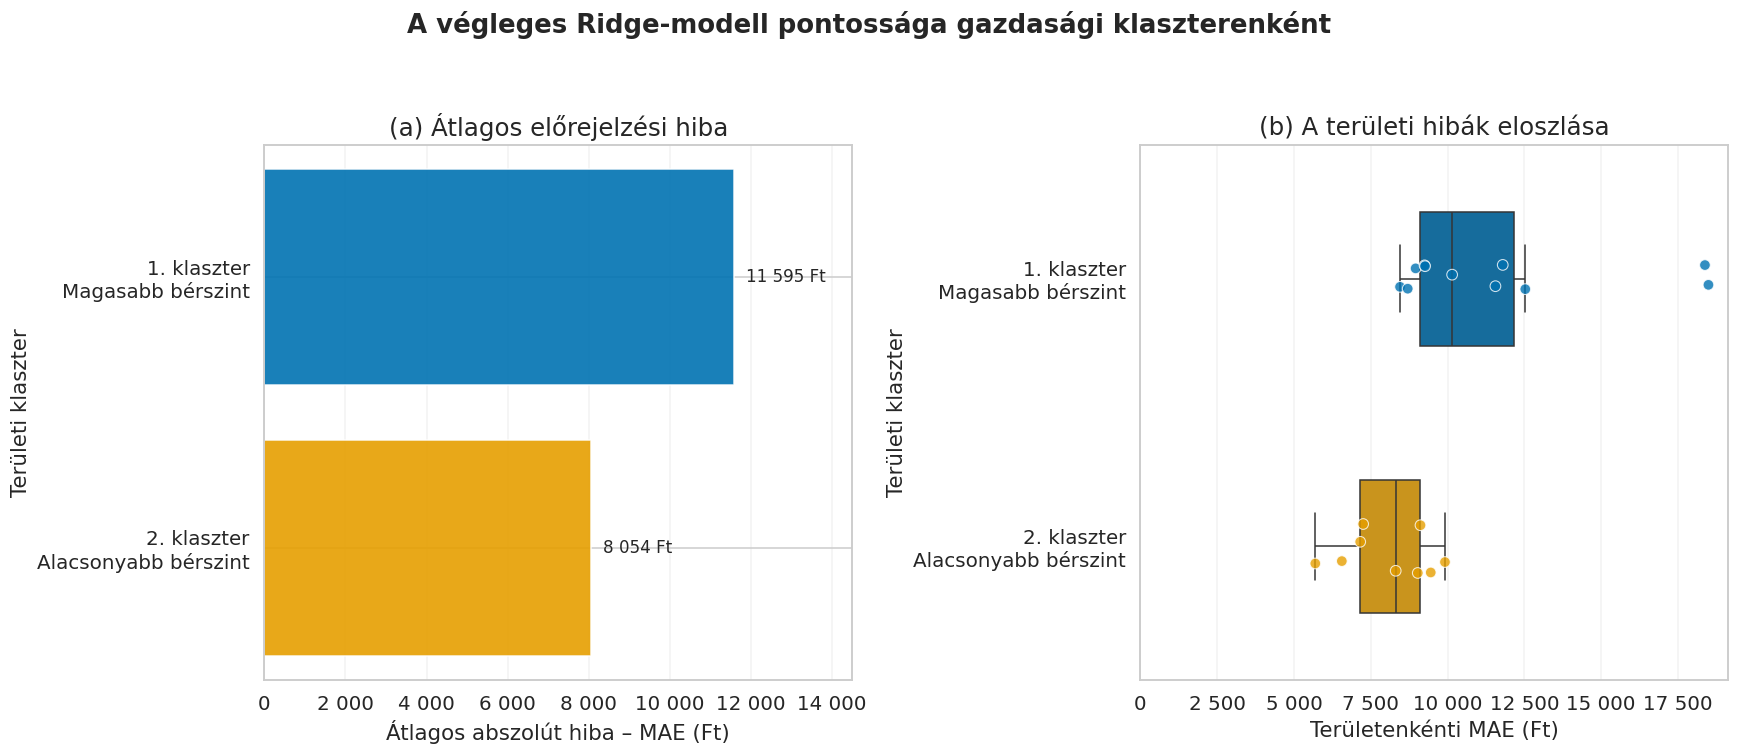

In [10]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 7)
)

# (A) KLASZTERENKÉNTI ÁTLAGOS MAE

cluster_plot_data = (
    cluster_error_summary
    .sort_values("Klaszter")
)

bars = axes[0].barh(
    cluster_plot_data[
        "Klaszter_megjelenítés"
    ],
    cluster_plot_data[
        "MAE_Ft"
    ],
    color=[
        CLUSTER_COLORS[label]
        for label in cluster_plot_data[
            "Klaszter_megjelenítés"
        ]
    ],
    alpha=0.9
)

maximum_cluster_mae = (
    cluster_plot_data[
        "MAE_Ft"
    ].max()
)

for bar, mae_value in zip(
    bars,
    cluster_plot_data["MAE_Ft"]
):
    axes[0].text(
        mae_value
        +
        maximum_cluster_mae * 0.025,
        bar.get_y()
        +
        bar.get_height() / 2,
        f"{mae_value:,.0f} Ft".replace(",", " "),
        va="center",
        fontsize=11
    )

axes[0].set_xlim(
    0,
    maximum_cluster_mae * 1.25
)

axes[0].invert_yaxis()

axes[0].xaxis.set_major_formatter(
    huf_formatter
)

axes[0].set_xlabel(
    "Átlagos abszolút hiba – MAE (Ft)"
)

axes[0].set_ylabel(
    "Területi klaszter"
)

axes[0].set_title(
    "(a) Átlagos előrejelzési hiba"
)

axes[0].grid(
    axis="x",
    alpha=0.25
)

# (B) A TERÜLETI MAE-K ELOSZLÁSA

sns.boxplot(
    data=regional_errors_clustered,
    x="MAE_Ft",
    y="Klaszter_megjelenítés",
    order=cluster_order,
    hue="Klaszter_megjelenítés",
    hue_order=cluster_order,
    palette=CLUSTER_COLORS,
    dodge=False,
    showfliers=False,
    width=0.5,
    legend=False,
    ax=axes[1]
)

sns.stripplot(
    data=regional_errors_clustered,
    x="MAE_Ft",
    y="Klaszter_megjelenítés",
    order=cluster_order,
    hue="Klaszter_megjelenítés",
    hue_order=cluster_order,
    palette=CLUSTER_COLORS,
    dodge=False,
    size=7,
    alpha=0.8,
    edgecolor="white",
    linewidth=0.7,
    legend=False,
    ax=axes[1]
)

axes[1].set_xlim(left=0)

axes[1].xaxis.set_major_formatter(
    huf_formatter
)

axes[1].set_xlabel(
    "Területenkénti MAE (Ft)"
)

axes[1].set_ylabel(
    "Területi klaszter"
)

axes[1].set_title(
    "(b) A területi hibák eloszlása"
)

axes[1].grid(
    axis="x",
    alpha=0.25
)

fig.suptitle(
    "A végleges Ridge-modell pontossága gazdasági klaszterenként",
    fontsize=17,
    fontweight="bold"
)

fig.tight_layout(
    rect=[0, 0, 1, 0.94]
)

fig.savefig(
    VIS_FIGURES / "02_klaszterenkenti_elorejelzesi_hiba.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    VIS_FIGURES / "02_klaszterenkenti_elorejelzesi_hiba.pdf",
    bbox_inches="tight"
)

plt.show()

In [11]:
cluster_error_summary.to_csv(
    VIS_RESULTS
    / "KSH_klaszterenkenti_elorejelzesi_hibak.csv",
    index=False,
    encoding="utf-8-sig"
)

regional_errors_clustered.to_csv(
    VIS_RESULTS
    / "KSH_teruleti_hibak_klaszterekkel.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "A klaszterenkénti hibaelemzés eredményei elmentve."
)

A klaszterenkénti hibaelemzés eredményei elmentve.


## 4.4. A bérszint és az előrejelzési hiba kapcsolata

A magasabb bérszintű klaszterben nagyobb abszolút előrejelzési hibát
figyeltünk meg. Ez azonban részben abból is következhet, hogy magasabb
bérszint mellett ugyanakkora relatív eltérés nagyobb forintban
kifejezett hibát eredményez.

Ezért az átlagos területi bérszint kapcsolatát két hibamutatóval
vizsgáljuk:

- az abszolút, forintban kifejezett MAE-vel;
- a bérszinthez viszonyított százalékos MAPE-vel.

Az elemzésben minden területi egység egyetlen megfigyelésként szerepel,
így a korrelációk 20 területi egység alapján kerülnek meghatározásra.

In [12]:
from scipy.stats import (
    pearsonr,
    spearmanr
)

wage_error_analysis = (
    regional_errors_clustered[
        [
            "Területi egység neve",
            "Klaszter",
            "Klaszter_neve",
            "Klaszter_megjelenítés",
            "Átlagos_valós_bér_Ft",
            "MAE_Ft",
            "MAPE_%",
            "Bias_Ft"
        ]
    ]
    .copy()
)

assert len(wage_error_analysis) == 20

assert not wage_error_analysis[
    "Területi egység neve"
].duplicated().any()

assert wage_error_analysis[
    [
        "Átlagos_valós_bér_Ft",
        "MAE_Ft",
        "MAPE_%"
    ]
].notna().all().all()

assert np.isfinite(
    wage_error_analysis[
        [
            "Átlagos_valós_bér_Ft",
            "MAE_Ft",
            "MAPE_%"
        ]
    ]
).all().all()

correlation_rows = []

error_metrics = {
    "MAE_Ft": "Abszolút hiba – MAE",
    "MAPE_%": "Relatív hiba – MAPE"
}

for metric_column, metric_name in error_metrics.items():

    pearson_result = pearsonr(
        wage_error_analysis[
            "Átlagos_valós_bér_Ft"
        ],
        wage_error_analysis[
            metric_column
        ]
    )

    spearman_result = spearmanr(
        wage_error_analysis[
            "Átlagos_valós_bér_Ft"
        ],
        wage_error_analysis[
            metric_column
        ]
    )

    correlation_rows.append(
        {
            "Hibamutató": metric_name,
            "Területek": len(
                wage_error_analysis
            ),
            "Pearson_r": pearson_result.statistic,
            "Pearson_p": pearson_result.pvalue,
            "Spearman_rho": spearman_result.statistic,
            "Spearman_p": spearman_result.pvalue
        }
    )

wage_error_correlations = pd.DataFrame(
    correlation_rows
)

display(
    wage_error_correlations.round(4)
)

,Hibamutató,Területek,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,Abszolút hiba – MAE,20,0.5806,0.0073,0.6857,0.0008
1,Relatív hiba – MAPE,20,0.2995,0.1995,0.3053,0.1906


In [13]:
mae_correlation = (
    wage_error_correlations.loc[
        wage_error_correlations[
            "Hibamutató"
        ]
        ==
        "Abszolút hiba – MAE"
    ]
    .iloc[0]
)

mape_correlation = (
    wage_error_correlations.loc[
        wage_error_correlations[
            "Hibamutató"
        ]
        ==
        "Relatív hiba – MAPE"
    ]
    .iloc[0]
)

print(
    "Bérszint és MAE – Pearson-korreláció:",
    f"{mae_correlation['Pearson_r']:.3f}",
    "| p-érték:",
    f"{mae_correlation['Pearson_p']:.4f}"
)

print(
    "Bérszint és MAE – Spearman-korreláció:",
    f"{mae_correlation['Spearman_rho']:.3f}",
    "| p-érték:",
    f"{mae_correlation['Spearman_p']:.4f}"
)

print()

print(
    "Bérszint és MAPE – Pearson-korreláció:",
    f"{mape_correlation['Pearson_r']:.3f}",
    "| p-érték:",
    f"{mape_correlation['Pearson_p']:.4f}"
)

print(
    "Bérszint és MAPE – Spearman-korreláció:",
    f"{mape_correlation['Spearman_rho']:.3f}",
    "| p-érték:",
    f"{mape_correlation['Spearman_p']:.4f}"
)

Bérszint és MAE – Pearson-korreláció: 0.581 | p-érték: 0.0073
Bérszint és MAE – Spearman-korreláció: 0.686 | p-érték: 0.0008

Bérszint és MAPE – Pearson-korreláció: 0.300 | p-érték: 0.1995
Bérszint és MAPE – Spearman-korreláció: 0.305 | p-érték: 0.1906


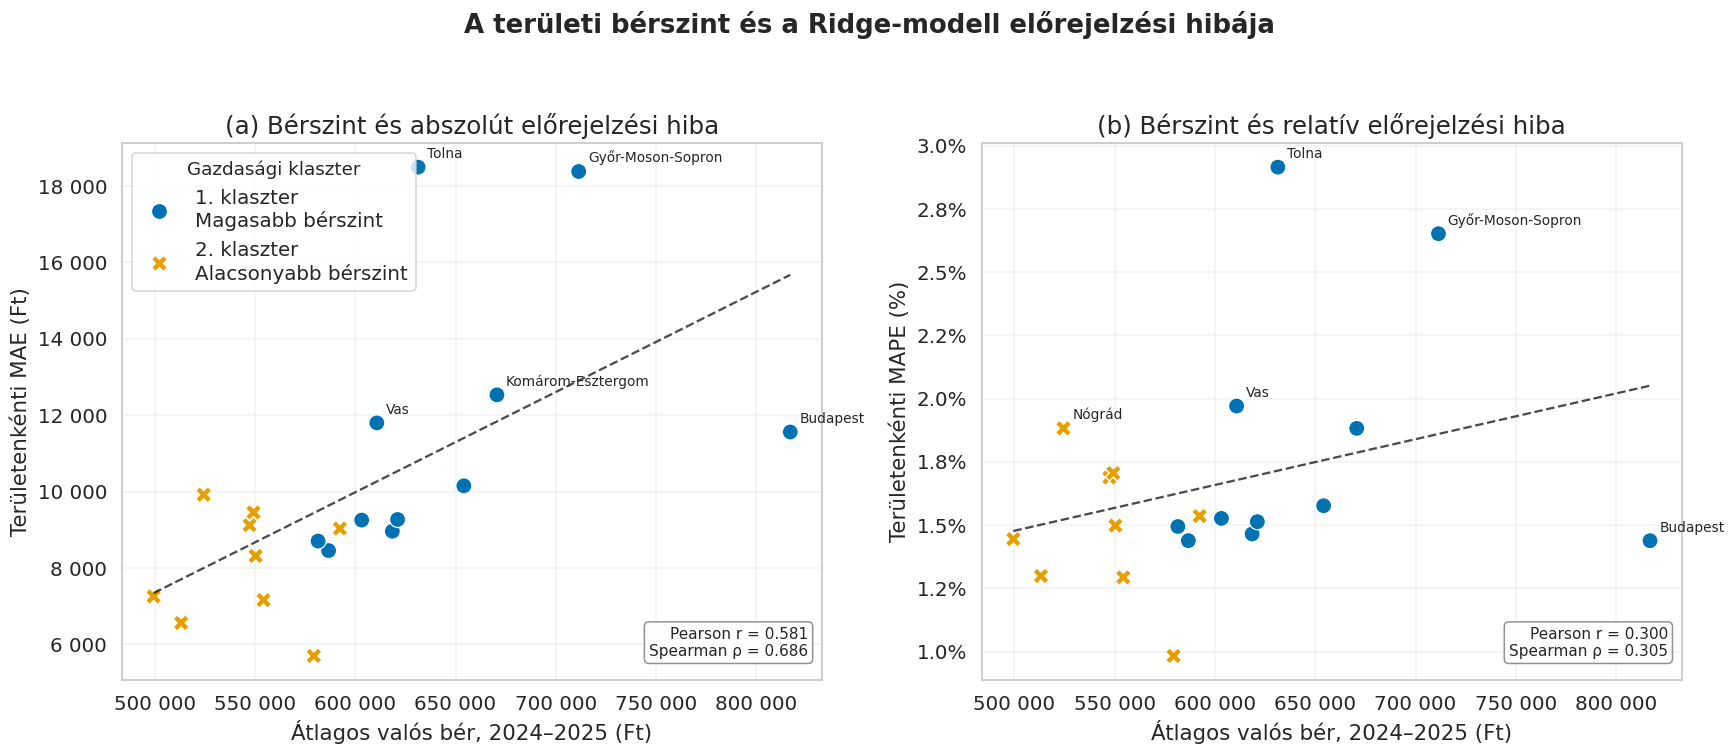

In [14]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 7)
)

# AZ ÁBRÁN KIEMELT TERÜLETEK

mae_label_regions = set(
    wage_error_analysis
    .nlargest(4, "MAE_Ft")
    ["Területi egység neve"]
)

mae_label_regions.add("Budapest")


mape_label_regions = set(
    wage_error_analysis
    .nlargest(4, "MAPE_%")
    ["Területi egység neve"]
)

mape_label_regions.add("Budapest")

# (A) BÉRSZINT ÉS ABSZOLÚT HIBA

sns.scatterplot(
    data=wage_error_analysis,
    x="Átlagos_valós_bér_Ft",
    y="MAE_Ft",
    hue="Klaszter_megjelenítés",
    hue_order=cluster_order,
    style="Klaszter_megjelenítés",
    style_order=cluster_order,
    palette=CLUSTER_COLORS,
    s=110,
    edgecolor="white",
    linewidth=0.8,
    ax=axes[0]
)

sns.regplot(
    data=wage_error_analysis,
    x="Átlagos_valós_bér_Ft",
    y="MAE_Ft",
    scatter=False,
    ci=None,
    color="black",
    line_kws={
        "linestyle": "--",
        "linewidth": 1.5,
        "alpha": 0.7
    },
    ax=axes[0]
)

for _, row in wage_error_analysis.loc[
    wage_error_analysis[
        "Területi egység neve"
    ].isin(mae_label_regions)
].iterrows():

    axes[0].annotate(
        row["Területi egység neve"],
        (
            row["Átlagos_valós_bér_Ft"],
            row["MAE_Ft"]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )


axes[0].xaxis.set_major_formatter(
    huf_formatter
)

axes[0].yaxis.set_major_formatter(
    huf_formatter
)

axes[0].set_xlabel(
    "Átlagos valós bér, 2024–2025 (Ft)"
)

axes[0].set_ylabel(
    "Területenkénti MAE (Ft)"
)

axes[0].set_title(
    "(a) Bérszint és abszolút előrejelzési hiba"
)

axes[0].legend(
    title="Gazdasági klaszter",
    loc="upper left",
    frameon=True
)

axes[0].grid(
    alpha=0.25
)


axes[0].text(
    0.98,
    0.04,
    (
        f"Pearson r = "
        f"{mae_correlation['Pearson_r']:.3f}\n"
        f"Spearman ρ = "
        f"{mae_correlation['Spearman_rho']:.3f}"
    ),
    transform=axes[0].transAxes,
    ha="right",
    va="bottom",
    fontsize=10,
    bbox={
        "boxstyle": "round",
        "facecolor": "white",
        "edgecolor": "grey",
        "alpha": 0.85
    }
)

# (B) BÉRSZINT ÉS RELATÍV HIBA

sns.scatterplot(
    data=wage_error_analysis,
    x="Átlagos_valós_bér_Ft",
    y="MAPE_%",
    hue="Klaszter_megjelenítés",
    hue_order=cluster_order,
    style="Klaszter_megjelenítés",
    style_order=cluster_order,
    palette=CLUSTER_COLORS,
    s=110,
    edgecolor="white",
    linewidth=0.8,
    legend=False,
    ax=axes[1]
)

sns.regplot(
    data=wage_error_analysis,
    x="Átlagos_valós_bér_Ft",
    y="MAPE_%",
    scatter=False,
    ci=None,
    color="black",
    line_kws={
        "linestyle": "--",
        "linewidth": 1.5,
        "alpha": 0.7
    },
    ax=axes[1]
)

for _, row in wage_error_analysis.loc[
    wage_error_analysis[
        "Területi egység neve"
    ].isin(mape_label_regions)
].iterrows():

    axes[1].annotate(
        row["Területi egység neve"],
        (
            row["Átlagos_valós_bér_Ft"],
            row["MAPE_%"]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

axes[1].xaxis.set_major_formatter(
    huf_formatter
)

axes[1].yaxis.set_major_formatter(
    FuncFormatter(
        lambda value, position:
            f"{value:.1f}%"
    )
)

axes[1].set_xlabel(
    "Átlagos valós bér, 2024–2025 (Ft)"
)

axes[1].set_ylabel(
    "Területenkénti MAPE (%)"
)

axes[1].set_title(
    "(b) Bérszint és relatív előrejelzési hiba"
)

axes[1].grid(
    alpha=0.25
)

axes[1].text(
    0.98,
    0.04,
    (
        f"Pearson r = "
        f"{mape_correlation['Pearson_r']:.3f}\n"
        f"Spearman ρ = "
        f"{mape_correlation['Spearman_rho']:.3f}"
    ),
    transform=axes[1].transAxes,
    ha="right",
    va="bottom",
    fontsize=10,
    bbox={
        "boxstyle": "round",
        "facecolor": "white",
        "edgecolor": "grey",
        "alpha": 0.85
    }
)

fig.suptitle(
    "A területi bérszint és a Ridge-modell előrejelzési hibája",
    fontsize=17,
    fontweight="bold"
)

fig.tight_layout(
    rect=[0, 0, 1, 0.94]
)

fig.savefig(
    VIS_FIGURES / "03_berszint_es_elorejelzesi_hiba.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    VIS_FIGURES / "03_berszint_es_elorejelzesi_hiba.pdf",
    bbox_inches="tight"
)

plt.show()

In [15]:
wage_error_analysis.to_csv(
    VIS_RESULTS
    / "KSH_berszint_es_teruleti_elorejelzesi_hiba.csv",
    index=False,
    encoding="utf-8-sig"
)

wage_error_correlations.to_csv(
    VIS_RESULTS
    / "KSH_berszint_hiba_korrelaciok.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "A bérszint és az előrejelzési hiba "
    "kapcsolatának eredményei elmentve."
)

A bérszint és az előrejelzési hiba kapcsolatának eredményei elmentve.


### Értelmezés

Az átlagos területi bérszint és a forintban kifejezett MAE között
közepesen erős pozitív kapcsolat figyelhető meg. A Pearson- és
Spearman-korreláció egyaránt statisztikailag szignifikáns, vagyis
a magasabb bérszintű területeken általában nagyobb az abszolút,
forintban mért előrejelzési hiba.

A bérszint és a százalékos MAPE közötti kapcsolat ugyanakkor
lényegesen gyengébb, és az 5%-os szignifikanciaszinten nem
szignifikáns. Ez arra utal, hogy a magasabb bérszintű klaszter
nagyobb MAE-je részben skálahatásból ered: magasabb bér mellett
hasonló relatív eltérés nagyobb forintösszeget jelent.

Az eredmények alapján ezért nem állítható, hogy a modell általánosan
rosszabbul működik a magasabb bérszintű területeken. A nagyobb
abszolút hibát néhány kiugró terület, különösen Tolna és
Győr-Moson-Sopron eredménye is növeli. A feltárt kapcsolatok
prediktív összefüggések, nem értelmezhetők oksági hatásként.

## 4.5. A klaszterenkénti előrejelzési hiba időbeli alakulása

Az előző elemzések alapján a végleges Ridge-modell összességében
felülbecsülte a 2024–2025-ös béreket. Ebben a részben azt vizsgáljuk,
hogy ez a torzítás mindkét gazdasági klasztert hasonlóan érintette-e,
illetve mely negyedévekben alakult ki a legnagyobb eltérés.

Az irányított átlagos hiba, vagyis a bias pozitív értéke felülbecslést,
negatív értéke pedig alulbecslést jelent. A bias mellett az abszolút
előrejelzési hibát is bemutatjuk, mivel az ellentétes irányú hibák
az átlagos bias értékében részben kiegyenlíthetik egymást.

In [16]:
quarterly_cluster_errors = (
    ridge_errors_clustered
    .groupby(
        [
            "Cél_Dátum",
            "Célnegyedév",
            "Klaszter",
            "Klaszter_neve"
        ],
        as_index=False
    )
    .agg(
        Területek=(
            "Területi egység neve",
            "nunique"
        ),

        Átlagos_valós_bér_Ft=(
            "Valós_bér",
            "mean"
        ),

        Bias_Ft=(
            "Hiba",
            "mean"
        ),

        Medián_hiba_Ft=(
            "Hiba",
            "median"
        ),

        MAE_Ft=(
            "Abszolút_hiba",
            "mean"
        ),

        Átlagos_négyzetes_hiba=(
            "Hiba",
            lambda values: np.mean(
                np.square(values)
            )
        ),

        MAPE_pct=(
            "APE_%",
            "mean"
        ),

        Felülbecslések_aránya=(
            "Felülbecslés",
            "mean"
        )
    )
    .sort_values(
        [
            "Cél_Dátum",
            "Klaszter"
        ]
    )
    .reset_index(drop=True)
)

quarterly_cluster_errors[
    "RMSE_Ft"
] = np.sqrt(
    quarterly_cluster_errors[
        "Átlagos_négyzetes_hiba"
    ]
)


quarterly_cluster_errors[
    "Felülbecslések_aránya_pct"
] = (
    quarterly_cluster_errors[
        "Felülbecslések_aránya"
    ]
    *
    100
)

quarterly_cluster_errors = (
    quarterly_cluster_errors
    .drop(
        columns=[
            "Átlagos_négyzetes_hiba",
            "Felülbecslések_aránya"
        ]
    )
)

quarterly_cluster_errors[
    "Klaszter_megjelenítés"
] = (
    quarterly_cluster_errors[
        "Klaszter"
    ]
    .map(CLUSTER_LABELS)
)

assert len(quarterly_cluster_errors) == 16

assert quarterly_cluster_errors[
    "Cél_Dátum"
].nunique() == 8

assert (
    quarterly_cluster_errors
    .groupby("Cél_Dátum")
    ["Klaszter"]
    .nunique()
    .eq(2)
    .all()
)

assert (
    quarterly_cluster_errors.loc[
        quarterly_cluster_errors[
            "Klaszter"
        ] == 1,
        "Területek"
    ]
    .eq(11)
    .all()
)

assert (
    quarterly_cluster_errors.loc[
        quarterly_cluster_errors[
            "Klaszter"
        ] == 2,
        "Területek"
    ]
    .eq(9)
    .all()
)


display(
    quarterly_cluster_errors[
        [
            "Célnegyedév",
            "Klaszter",
            "Klaszter_neve",
            "Területek",
            "Bias_Ft",
            "MAE_Ft",
            "RMSE_Ft",
            "MAPE_pct",
            "Felülbecslések_aránya_pct"
        ]
    ]
    .round(2)
)

,Célnegyedév,Klaszter,Klaszter_neve,Területek,Bias_Ft,MAE_Ft,RMSE_Ft,MAPE_pct,Felülbecslések_aránya_pct
0,2024Q1,1,Magasabb bérszint / alacsonyabb munkanélküliség,11,2871.00,4829.54,6494.40,0.84,63.64
1,2024Q1,2,Alacsonyabb bérszint / magasabb munkanélküliség,9,-1521.62,4893.60,5807.40,0.98,44.44
2,2024Q2,1,Magasabb bérszint / alacsonyabb munkanélküliség,11,775.93,6892.72,10040.45,1.10,72.73
3,2024Q2,2,Alacsonyabb bérszint / magasabb munkanélküliség,9,890.74,3944.10,4762.14,0.77,33.33
4,2024Q3,1,Magasabb bérszint / alacsonyabb munkanélküliség,11,17810.40,17810.40,20782.56,2.87,100.00
5,2024Q3,2,Alacsonyabb bérszint / magasabb munkanélküliség,9,7207.61,7207.61,7623.34,1.40,100.00
6,2024Q4,1,Magasabb bérszint / alacsonyabb munkanélküliség,11,6411.67,6411.67,8078.93,1.02,100.00
7,2024Q4,2,Alacsonyabb bérszint / magasabb munkanélküliség,9,9740.21,9740.21,10228.33,1.78,100.00
8,2025Q1,1,Magasabb bérszint / alacsonyabb munkanélküliség,11,24941.94,24941.94,25467.11,3.92,100.00
9,2025Q1,2,Alacsonyabb bérszint / magasabb munkanélküliség,9,19466.03,19466.03,19770.82,3.57,100.00


In [17]:
worst_quarter_by_cluster = (
    quarterly_cluster_errors
    .sort_values(
        [
            "Klaszter",
            "MAE_Ft"
        ],
        ascending=[
            True,
            False
        ]
    )
    .drop_duplicates(
        subset="Klaszter",
        keep="first"
    )
    .sort_values("Klaszter")
    .reset_index(drop=True)
)

print(
    "A legnagyobb MAE-t mutató negyedév "
    "klaszterenként:"
)

display(
    worst_quarter_by_cluster[
        [
            "Klaszter",
            "Klaszter_neve",
            "Célnegyedév",
            "Bias_Ft",
            "MAE_Ft",
            "MAPE_pct",
            "Felülbecslések_aránya_pct"
        ]
    ]
    .round(2)
)

critical_quarter = (
    quarterly_cluster_errors.loc[
        quarterly_cluster_errors[
            "Cél_Dátum"
        ]
        ==
        pd.Timestamp("2025-01-01")
    ]
    .copy()
)

assert len(critical_quarter) == 2

print(
    "A 2025 Q1-es negyedév klaszterenként:"
)

display(
    critical_quarter[
        [
            "Klaszter",
            "Klaszter_neve",
            "Bias_Ft",
            "MAE_Ft",
            "MAPE_pct",
            "Felülbecslések_aránya_pct"
        ]
    ]
    .round(2)
)

A legnagyobb MAE-t mutató negyedév klaszterenként:


,Klaszter,Klaszter_neve,Célnegyedév,Bias_Ft,MAE_Ft,MAPE_pct,Felülbecslések_aránya_pct
0,1,Magasabb bérszint / alacsonyabb munkanélküliség,2025Q1,24941.94,24941.94,3.92,100.0
1,2,Alacsonyabb bérszint / magasabb munkanélküliség,2025Q1,19466.03,19466.03,3.57,100.0


A 2025 Q1-es negyedév klaszterenként:


,Klaszter,Klaszter_neve,Bias_Ft,MAE_Ft,MAPE_pct,Felülbecslések_aránya_pct
8,1,Magasabb bérszint / alacsonyabb munkanélküliség,24941.94,24941.94,3.92,100.0
9,2,Alacsonyabb bérszint / magasabb munkanélküliség,19466.03,19466.03,3.57,100.0


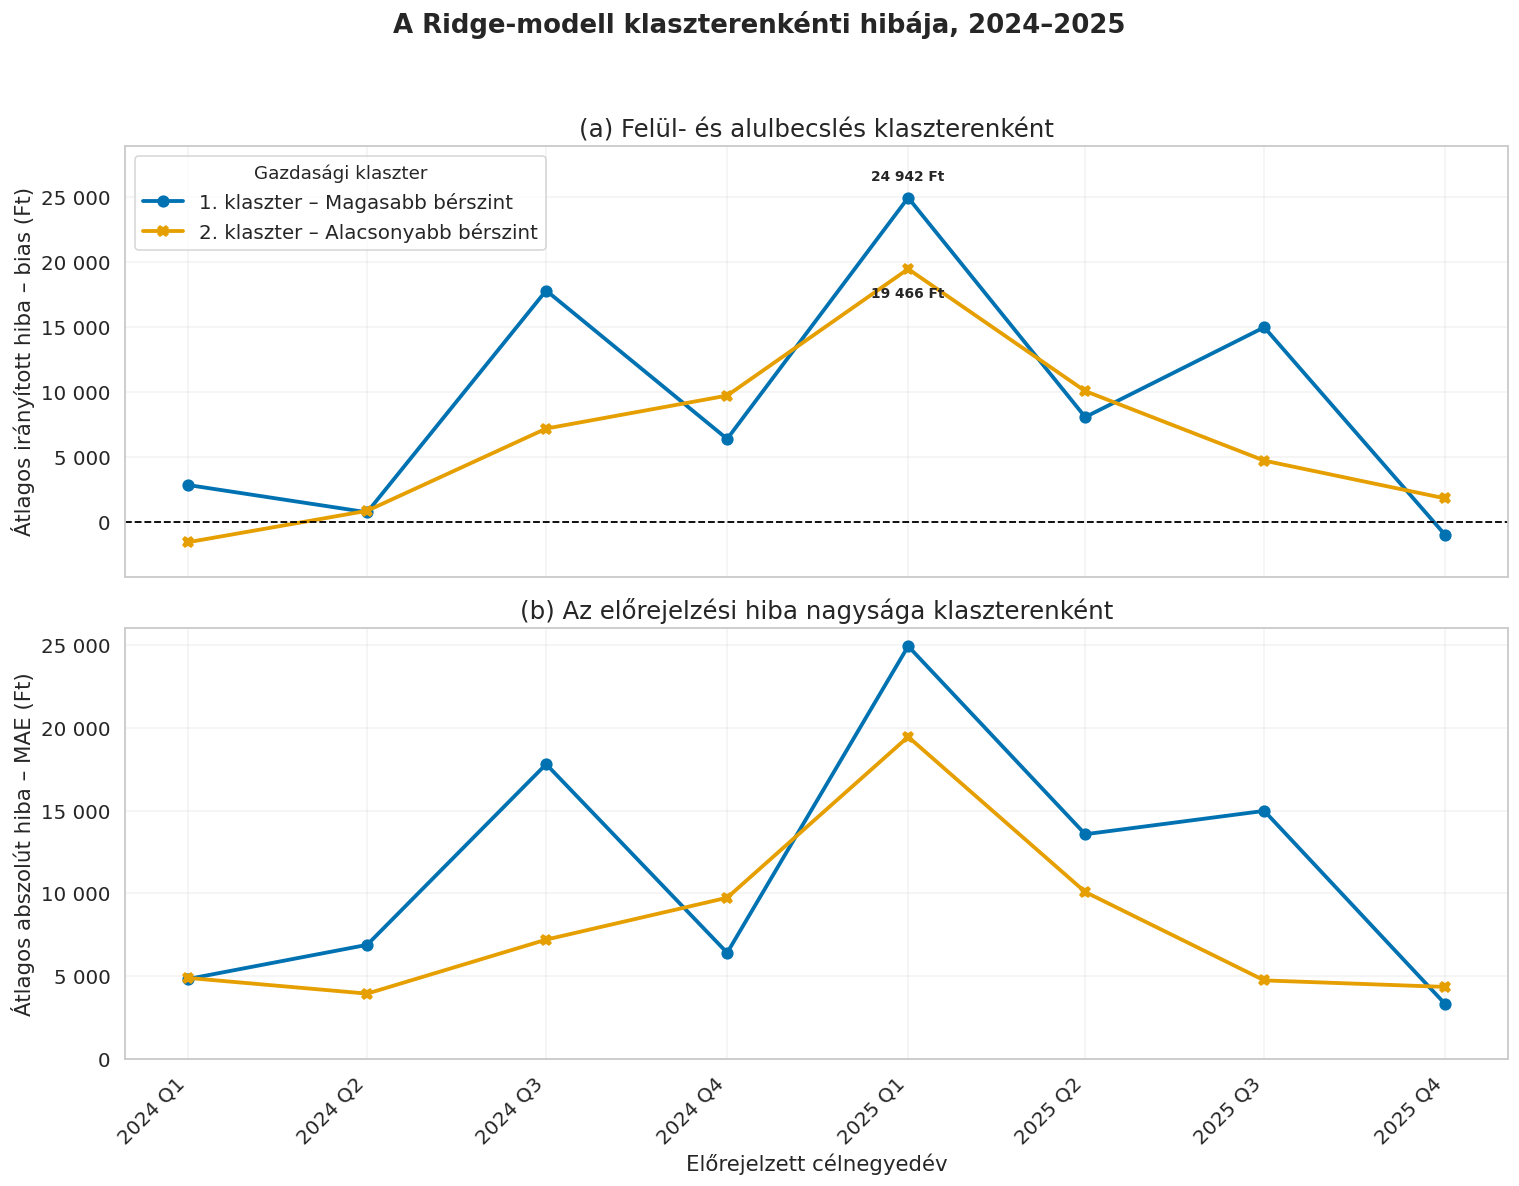

In [18]:
CLUSTER_MARKERS = {
    CLUSTER_LABELS[1]: "o",
    CLUSTER_LABELS[2]: "X"
}

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(14, 11),
    sharex=True
)

# (A) ÁTLAGOS IRÁNYÍTOTT HIBA – BIAS

for cluster_label in cluster_order:

    cluster_time_data = (
        quarterly_cluster_errors.loc[
            quarterly_cluster_errors[
                "Klaszter_megjelenítés"
            ]
            ==
            cluster_label
        ]
        .sort_values("Cél_Dátum")
    )

    axes[0].plot(
        cluster_time_data["Cél_Dátum"],
        cluster_time_data["Bias_Ft"],
        color=CLUSTER_COLORS[cluster_label],
        marker=CLUSTER_MARKERS[cluster_label],
        markersize=7,
        linewidth=2.5,
        label=cluster_label.replace("\n", " – ")
    )

axes[0].axhline(
    0,
    color="black",
    linewidth=1.2,
    linestyle="--"
)

minimum_bias = (
    quarterly_cluster_errors[
        "Bias_Ft"
    ]
    .min()
)

maximum_bias = (
    quarterly_cluster_errors[
        "Bias_Ft"
    ]
    .max()
)

bias_range = (
    maximum_bias
    -
    minimum_bias
)

axes[0].set_ylim(
    min(
        -3000,
        minimum_bias
        -
        bias_range * 0.10
    ),
    maximum_bias
    +
    bias_range * 0.15
)

axes[0].yaxis.set_major_formatter(
    huf_formatter
)

axes[0].set_ylabel(
    "Átlagos irányított hiba – bias (Ft)"
)

axes[0].set_title(
    "(a) Felül- és alulbecslés klaszterenként"
)

axes[0].legend(
    title="Gazdasági klaszter",
    loc="upper left",
    frameon=True
)

axes[0].grid(
    alpha=0.25
)

# A 2025 Q1-ES ÉRTÉKEK KIEMELÉSE

annotation_offsets = {
    1: (0, 11),
    2: (0, -19)
}


for _, row in critical_quarter.iterrows():

    axes[0].annotate(
        f"{row['Bias_Ft']:,.0f} Ft".replace(",", " "),
        (
            row["Cél_Dátum"],
            row["Bias_Ft"]
        ),
        xytext=annotation_offsets[
            int(row["Klaszter"])
        ],
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

# (B) ABSZOLÚT ELŐREJELZÉSI HIBA – MAE

for cluster_label in cluster_order:

    cluster_time_data = (
        quarterly_cluster_errors.loc[
            quarterly_cluster_errors[
                "Klaszter_megjelenítés"
            ]
            ==
            cluster_label
        ]
        .sort_values("Cél_Dátum")
    )

    axes[1].plot(
        cluster_time_data["Cél_Dátum"],
        cluster_time_data["MAE_Ft"],
        color=CLUSTER_COLORS[cluster_label],
        marker=CLUSTER_MARKERS[cluster_label],
        markersize=7,
        linewidth=2.5,
        label=cluster_label.replace("\n", " – ")
    )

axes[1].set_ylim(bottom=0)

axes[1].yaxis.set_major_formatter(
    huf_formatter
)

axes[1].set_xlabel(
    "Előrejelzett célnegyedév"
)

axes[1].set_ylabel(
    "Átlagos abszolút hiba – MAE (Ft)"
)

axes[1].set_title(
    "(b) Az előrejelzési hiba nagysága klaszterenként"
)

axes[1].grid(
    alpha=0.25
)


axes[1].set_xticks(
    target_dates
)

axes[1].set_xticklabels(
    quarter_labels,
    rotation=45,
    ha="right"
)


fig.suptitle(
    "A Ridge-modell klaszterenkénti hibája, 2024–2025",
    fontsize=17,
    fontweight="bold"
)


fig.tight_layout(
    rect=[0, 0, 1, 0.95]
)


fig.savefig(
    VIS_FIGURES
    / "04_klaszterenkenti_hiba_idobeli_alakulasa.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    VIS_FIGURES
    / "04_klaszterenkenti_hiba_idobeli_alakulasa.pdf",
    bbox_inches="tight"
)

plt.show()

In [19]:
quarterly_cluster_errors.to_csv(
    VIS_RESULTS
    / "KSH_klaszterenkenti_negyedeves_hibak.csv",
    index=False,
    encoding="utf-8-sig"
)

worst_quarter_by_cluster.to_csv(
    VIS_RESULTS
    / "KSH_klaszterenkenti_legnehezebb_negyedevek.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "A klaszterenkénti időbeli hibaelemzés "
    "eredményei elmentve."
)

A klaszterenkénti időbeli hibaelemzés eredményei elmentve.


### Értelmezés

A 2025 első negyedéve mindkét gazdasági klaszterben a legnagyobb
előrejelzési hibát eredményezte. Ebben a negyedévben a modell mind
a 20 területi egység bérét felülbecsülte, ezért a hiba nem egyetlen
klaszter vagy néhány kiugró vármegye sajátossága volt.

A magasabb bérszintű klaszterben a 2025 Q1-es MAE közel 25 ezer Ft,
az alacsonyabb bérszintű klaszterben pedig körülbelül 19,5 ezer Ft
volt. A relatív hibák közötti eltérés ennél kisebb volt: 3,92%,
illetve 3,57%.

A két klaszter hibája több negyedévben azonos irányban változott,
ami közös időbeli és gazdasági hatások jelenlétére utal. A magasabb
bérszintű klaszter ugyanakkor 2024 Q3-ban és 2025 Q3-ban is nagyobb
hibát mutatott. A 2025 Q4-es eredmények alapján a modell pontossága
mindkét klaszterben jelentősen javult.

## 4.6. A végleges Ridge-modell legfontosabb feature-hatásai

A modell értelmezhetőségének vizsgálatához a nyolc végső
walk-forward fold Ridge-együtthatóit használjuk fel.

A különböző mértékegységű numerikus változók összehasonlíthatósága
érdekében az együtthatókat a transzformált feature-ek egy
szórásnyi változására vetítjük. A pozitív érték magasabb, a negatív
érték alacsonyabb előrejelzett bérrel jár együtt, a többi változó
változatlansága mellett.

A hibavonalak a nyolc végső fold között tapasztalt szórást mutatják.
Az eredmények prediktív kapcsolatokat fejeznek ki, és nem
értelmezhetők oksági hatásokként.

In [20]:
CATEGORICAL_BASELINES_FILE = (
    ML_RESULTS
    / "KSH_final_ridge_categorical_baselines.csv"
)

assert CATEGORICAL_BASELINES_FILE.exists()

categorical_baselines = read_csv_clean(
    CATEGORICAL_BASELINES_FILE
)

assert {
    "Kategorikus_feature",
    "Referenciakategória"
}.issubset(
    categorical_baselines.columns
)

baseline_lookup = dict(
    zip(
        categorical_baselines[
            "Kategorikus_feature"
        ],
        categorical_baselines[
            "Referenciakategória"
        ]
    )
)

assert baseline_lookup[
    "Negyedév_kategória"
] == "Q1"

assert baseline_lookup[
    "Területi egység neve"
] == "Baranya"

print(
    "Kategorikus referenciakategóriák:"
)

display(categorical_baselines)

# KÖZÉRTHETŐ FEATURE-NEVEK

FEATURE_LABELS = {
    "Bruttó_átlagkereset_HUF":
        "Aktuális negyedévi bér",

    "Bér_Lag1":
        "Bér – 1 negyedéves késleltetés",

    "Bér_Lag2":
        "Bér – 2 negyedéves késleltetés",

    "Bér_Lag3":
        "Bér – 3 negyedéves késleltetés",

    "Bér_Lag4":
        "Bér – 4 negyedéves késleltetés",

    "Bér_Növekedés_QoQ":
        "Negyedéves bérnövekedés",

    "Bér_Növekedés_YoY":
        "Éves bérnövekedés",

    "Munkanélküliségi_ráta_%":
        "Munkanélküliségi ráta",

    "Munkanélküliség_Lag1":
        "Munkanélküliség – 1 negyedéves késleltetés",

    "Munkanélküliség_Lag4":
        "Munkanélküliség – 4 negyedéves késleltetés",

    "Munkanélküliség_Delta":
        "Munkanélküliség negyedéves változása",

    "Álláskeresők_1000_foglalkoztatottra":
        "Álláskeresők / 1000 foglalkoztatott"
}

def format_feature_name(feature_name):

    if feature_name in FEATURE_LABELS:
        return FEATURE_LABELS[
            feature_name
        ]

    if feature_name.startswith(
        "Területi egység neve_"
    ):
        return (
            "Terület: "
            +
            feature_name.replace(
                "Területi egység neve_",
                ""
            )
        )

    if feature_name.startswith(
        "Negyedév_kategória_"
    ):
        return (
            "Szezonalitás: "
            +
            feature_name.replace(
                "Negyedév_kategória_",
                ""
            )
            +
            " – Q1-hez képest"
        )

    return feature_name.replace(
        "_",
        " "
    )

top_feature_effects = (
    coefficient_summary
    .nlargest(
        12,
        "Abszolút_átlagos_hatás_1SD_Ft"
    )
    .copy()
)

top_feature_effects[
    "Feature_megjelenítés"
] = (
    top_feature_effects[
        "Feature"
    ]
    .map(format_feature_name)
)

assert len(top_feature_effects) == 12

assert top_feature_effects[
    "Foldok"
].eq(8).all()

display(
    top_feature_effects[
        [
            "Hatás_rangsor",
            "Feature_megjelenítés",
            "Feature_csoport",
            "Átlagos_hatás_1SD_Ft",
            "Hatás_1SD_szórás_Ft",
            "Előjel_stabilitás"
        ]
    ]
    .round(2)
)

Kategorikus referenciakategóriák:


,Kategorikus_feature,Referenciakategória
0,Negyedév_kategória,Q1
1,Területi egység neve,Baranya


,Hatás_rangsor,Feature_megjelenítés,Feature_csoport,Átlagos_hatás_1SD_Ft,Hatás_1SD_szórás_Ft,Előjel_stabilitás
0,1,Bér – 3 negyedéves késleltetés,Bérdinamika,39203.79,4870.04,Mindig pozitív
1,2,Bér – 1 negyedéves késleltetés,Bérdinamika,21432.63,4221.39,Mindig pozitív
2,3,Aktuális negyedévi bér,Bérdinamika,16012.23,2283.37,Mindig pozitív
3,4,Bér – 4 negyedéves késleltetés,Bérdinamika,14769.58,1345.30,Mindig pozitív
4,5,Bér – 2 negyedéves késleltetés,Bérdinamika,9814.71,1008.94,Mindig pozitív
5,6,Szezonalitás: Q2 – Q1-hez képest,Negyedéves szezonalitás,-4520.96,234.04,Mindig negatív
6,7,Éves bérnövekedés,Bérdinamika,3822.85,907.39,Mindig pozitív
7,8,Szezonalitás: Q3 – Q1-hez képest,Negyedéves szezonalitás,2947.54,197.86,Mindig pozitív
8,9,Álláskeresők / 1000 foglalkoztatott,Munkaerőpiac,-2223.70,743.29,Mindig negatív
9,10,Terület: Budapest,Területi kategória,-1553.46,817.91,Mindig negatív


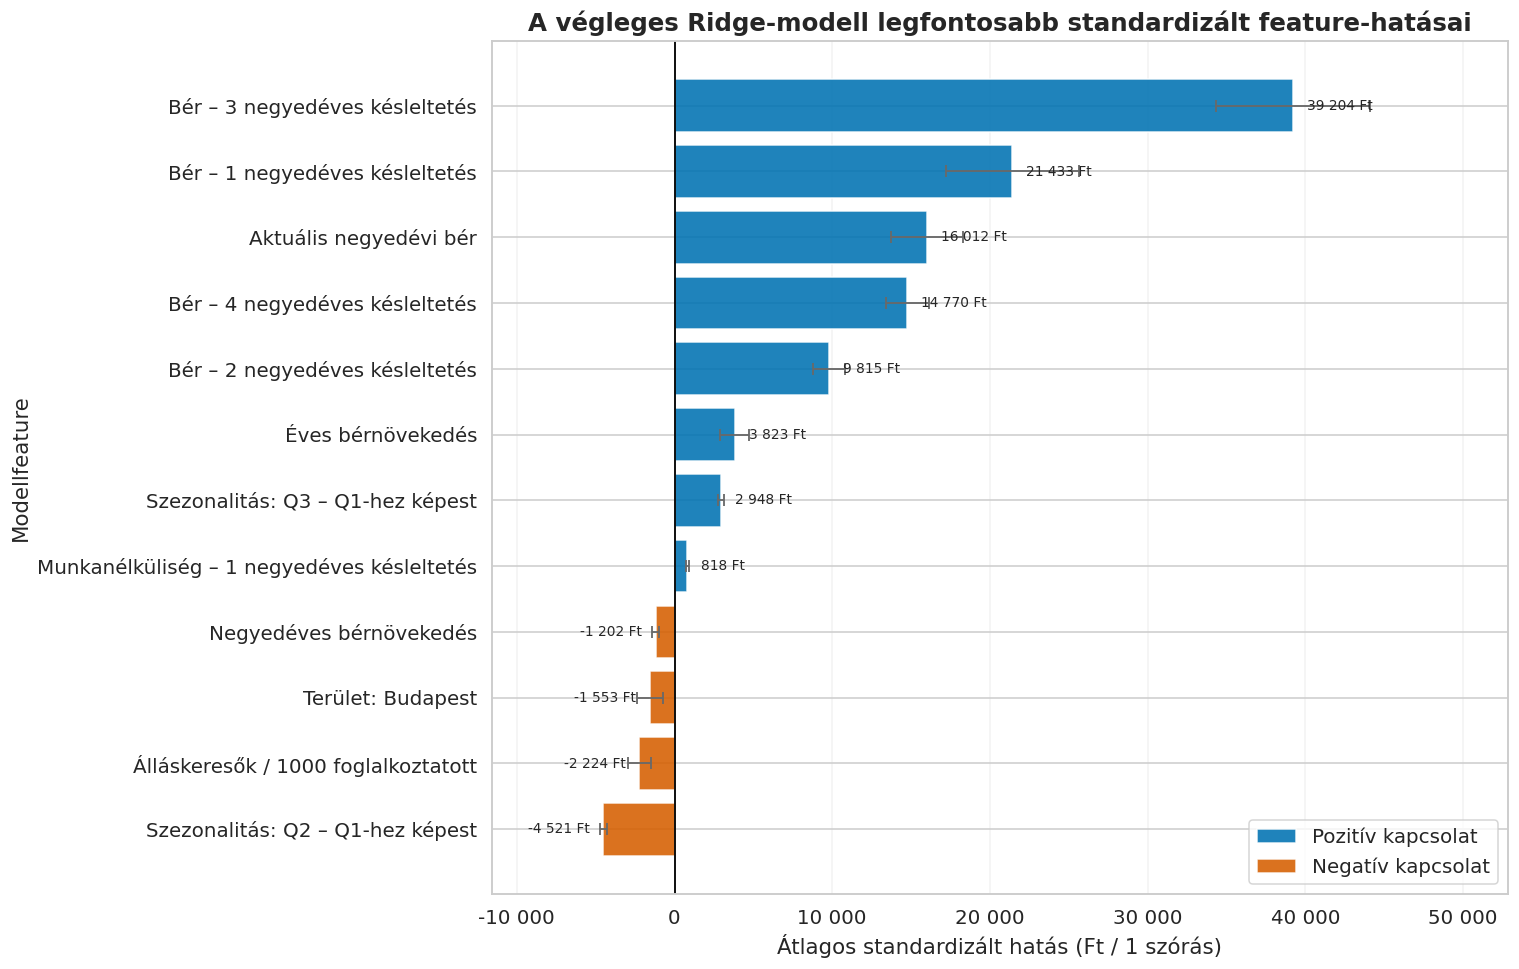

In [21]:
from matplotlib.patches import Patch

feature_plot_data = (
    top_feature_effects
    .sort_values(
        "Átlagos_hatás_1SD_Ft"
    )
    .copy()
)

POSITIVE_EFFECT_COLOR = "#0072B2"
NEGATIVE_EFFECT_COLOR = "#D55E00"

effect_colors = np.where(
    feature_plot_data[
        "Átlagos_hatás_1SD_Ft"
    ]
    >= 0,
    POSITIVE_EFFECT_COLOR,
    NEGATIVE_EFFECT_COLOR
)

fig, ax = plt.subplots(
    figsize=(14, 9)
)

bars = ax.barh(
    feature_plot_data[
        "Feature_megjelenítés"
    ],
    feature_plot_data[
        "Átlagos_hatás_1SD_Ft"
    ],
    xerr=feature_plot_data[
        "Hatás_1SD_szórás_Ft"
    ],
    color=effect_colors,
    alpha=0.88,
    capsize=4,
    error_kw={
        "ecolor": "dimgray",
        "elinewidth": 1.2,
        "capthick": 1.2
    }
)

ax.axvline(
    0,
    color="black",
    linewidth=1.2
)

minimum_effect = (
    feature_plot_data[
        "Átlagos_hatás_1SD_Ft"
    ]
    -
    feature_plot_data[
        "Hatás_1SD_szórás_Ft"
    ]
).min()

maximum_effect = (
    feature_plot_data[
        "Átlagos_hatás_1SD_Ft"
    ]
    +
    feature_plot_data[
        "Hatás_1SD_szórás_Ft"
    ]
).max()

effect_range = (
    maximum_effect
    -
    minimum_effect
)

ax.set_xlim(
    minimum_effect
    -
    effect_range * 0.14,
    maximum_effect
    +
    effect_range * 0.18
)

label_offset = (
    effect_range
    *
    0.018
)

for bar, effect_value in zip(
    bars,
    feature_plot_data[
        "Átlagos_hatás_1SD_Ft"
    ]
):

    ax.text(
        (
            effect_value
            +
            label_offset

            if effect_value >= 0

            else effect_value
            -
            label_offset
        ),
        bar.get_y()
        +
        bar.get_height() / 2,
        f"{effect_value:,.0f} Ft".replace(",", " "),
        va="center",
        ha=(
            "left"
            if effect_value >= 0
            else "right"
        ),
        fontsize=9
    )

ax.xaxis.set_major_formatter(
    huf_formatter
)

ax.set_xlabel(
    "Átlagos standardizált hatás (Ft / 1 szórás)"
)

ax.set_ylabel(
    "Modellfeature"
)

ax.set_title(
    "A végleges Ridge-modell legfontosabb standardizált feature-hatásai",
    fontsize=16,
    fontweight="bold"
)

ax.grid(
    axis="x",
    alpha=0.25
)

legend_elements = [
    Patch(
        facecolor=POSITIVE_EFFECT_COLOR,
        alpha=0.88,
        label="Pozitív kapcsolat"
    ),

    Patch(
        facecolor=NEGATIVE_EFFECT_COLOR,
        alpha=0.88,
        label="Negatív kapcsolat"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower right",
    frameon=True
)

fig.tight_layout()


fig.savefig(
    VIS_FIGURES
    / "05_ridge_legfontosabb_feature_hatasok.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    VIS_FIGURES
    / "05_ridge_legfontosabb_feature_hatasok.pdf",
    bbox_inches="tight"
)

plt.show()

In [22]:
top_feature_effects.to_csv(
    VIS_RESULTS
    / "KSH_ridge_legfontosabb_feature_hatasok.csv",
    index=False,
    encoding="utf-8-sig"
)

categorical_baselines.to_csv(
    VIS_RESULTS
    / "KSH_ridge_kategorikus_referenciakategoriak.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "A feature-hatások vizualizációs "
    "eredményei elmentve."
)

A feature-hatások vizualizációs eredményei elmentve.


### Értelmezés

A végleges Ridge-modell előrejelzéseit elsősorban a korábbi
bérértékek határozzák meg. A legnagyobb standardizált hatású
változó a három negyedévvel késleltetett bér, amelyet az egy-,
négy- és két negyedéves késleltetések, valamint az aktuális
negyedévi bér követ.

A három negyedéves késleltetés kiemelt jelentősége gazdaságilag
és időbelileg is értelmezhető: az egy negyedévvel későbbi célváltozó
szempontjából ez közelíti az előző év azonos célnegyedévének
bérszintjét. Ez a bérek erős időbeli folytonosságát és szezonális
szerkezetét mutatja.

A bérdinamikai változók hatása összességében lényegesen nagyobb,
mint a munkaerőpiaci és területi változóké. A kategorikus feature-ök
hatásait a referenciakategóriákhoz – Baranyához és az első
negyedévhez – viszonyítva kell értelmezni.

A one-hot kódolt kategorikus változók standardizált hatásának
nagyságát a kategóriák gyakorisága is befolyásolja, ezért ezek az
értékek nem azonosak a kategóriaváltás közvetlen, forintban mért
hatásával. Az együtthatók prediktív kapcsolatokat fejeznek ki,
és nem tekinthetők oksági becsléseknek.

## 4.7. A kutatás legfontosabb eredményeinek összefoglalása

Az alábbi összefoglaló tábla egyesíti a végleges teszt,
a benchmark-összehasonlítás, a területi hibaelemzés,
a klaszterenkénti vizsgálat és a feature-hatások
legfontosabb eredményeit.

In [23]:
# MODELLEREDMÉNYEK

final_ridge_result = (
    final_summary.loc[
        final_summary["Modell"]
        ==
        "Végleges Ridge"
    ]
    .iloc[0]
)

previous_naive_result = (
    final_summary.loc[
        final_summary["Modell"]
        ==
        "Naiv – előző negyedév"
    ]
    .iloc[0]
)

seasonal_naive_result = (
    final_summary.loc[
        final_summary["Modell"]
        ==
        "Szezonális naiv – előző év"
    ]
    .iloc[0]
)

ridge_mae = float(
    final_ridge_result[
        "Átlag_MAE"
    ]
)

previous_naive_improvement = (
    1
    -
    ridge_mae
    /
    float(
        previous_naive_result[
            "Átlag_MAE"
        ]
    )
) * 100

seasonal_naive_improvement = (
    1
    -
    ridge_mae
    /
    float(
        seasonal_naive_result[
            "Átlag_MAE"
        ]
    )
) * 100

# TERÜLETI EREDMÉNYEK

best_region = (
    regional_errors
    .nsmallest(
        1,
        "MAE_Ft"
    )
    .iloc[0]
)

worst_region = (
    regional_errors
    .nlargest(
        1,
        "MAE_Ft"
    )
    .iloc[0]
)

overall_bias_value = float(
    ridge_error_data[
        "Hiba"
    ]
    .mean()
)

overall_overestimation_rate = (
    ridge_error_data[
        "Hiba"
    ]
    .gt(0)
    .mean()
    *
    100
)

# LEGFONTOSABB FEATURE

top_feature = (
    coefficient_summary
    .nlargest(
        1,
        "Abszolút_átlagos_hatás_1SD_Ft"
    )
    .iloc[0]
)

# LEGNAGYOBB NEGYEDÉVES HIBA

worst_overall_quarter = (
    quarterly_bias
    .nlargest(
        1,
        "MAE_Ft"
    )
    .iloc[0]
)

notebook_4_summary = pd.DataFrame(
    [
        {
            "Témakör": "Végleges modell",
            "Eredmény": "Ridge-regresszió, alpha = 3"
        },

        {
            "Témakör": "Végső tesztidőszak",
            "Eredmény": "2024 Q1 – 2025 Q4"
        },

        {
            "Témakör": "Végső teszt MAE",
            "Eredmény": (
                f"{final_ridge_result['Átlag_MAE']:,.0f} Ft"
                .replace(",", " ")
            )
        },

        {
            "Témakör": "Végső teszt RMSE",
            "Eredmény": (
                f"{final_ridge_result['Összesített_RMSE']:,.0f} Ft"
                .replace(",", " ")
            )
        },

        {
            "Témakör": "Végső teszt MAPE",
            "Eredmény": (
                f"{final_ridge_result['MAPE_%']:.2f}%"
            )
        },

        {
            "Témakör": "Átlagos negyedéves R²",
            "Eredmény": (
                f"{final_ridge_result['Átlag_R2']:.3f}"
            )
        },

        {
            "Témakör": "Javulás az előző negyedéves naiv modellhez képest",
            "Eredmény": (
                f"{previous_naive_improvement:.1f}%"
            )
        },

        {
            "Témakör": "Javulás a szezonális naiv modellhez képest",
            "Eredmény": (
                f"{seasonal_naive_improvement:.1f}%"
            )
        },

        {
            "Témakör": "Átlagos irányított hiba",
            "Eredmény": (
                f"{overall_bias_value:,.0f} Ft"
                .replace(",", " ")
                +
                " – felülbecslés"
            )
        },

        {
            "Témakör": "Felülbecslések aránya",
            "Eredmény": (
                f"{overall_overestimation_rate:.1f}%"
            )
        },

        {
            "Témakör": "Legpontosabban előrejelzett terület",
            "Eredmény": (
                f"{best_region['Területi egység neve']} – "
                +
                f"{best_region['MAE_Ft']:,.0f} Ft MAE"
                .replace(",", " ")
            )
        },

        {
            "Témakör": "Legpontatlanabbul előrejelzett terület",
            "Eredmény": (
                f"{worst_region['Területi egység neve']} – "
                +
                f"{worst_region['MAE_Ft']:,.0f} Ft MAE"
                .replace(",", " ")
            )
        },

        {
        "Témakör": "Klaszterek közötti MAE-különbség",
        "Eredmény": (
            f"{cluster_mae_difference:,.0f} Ft"
            .replace(",", " ")
            +
            f"; az 1. klaszterben "
            f"{cluster_mae_difference_pct:.1f}% többlet"
        )
    },

        {
            "Témakör": "Bérszint és MAE kapcsolata",
            "Eredmény": (
                f"Pearson r = {mae_correlation['Pearson_r']:.3f}, "
                +
                f"p = {mae_correlation['Pearson_p']:.4f}"
            )
        },

        {
            "Témakör": "Bérszint és MAPE kapcsolata",
            "Eredmény": (
                f"Pearson r = {mape_correlation['Pearson_r']:.3f}, "
                +
                f"p = {mape_correlation['Pearson_p']:.4f}"
            )
        },

        {
            "Témakör": "Legnehezebb célnegyedév",
            "Eredmény": (
                f"{worst_overall_quarter['Célnegyedév']} – "
                +
                f"{worst_overall_quarter['MAE_Ft']:,.0f} Ft MAE"
                .replace(",", " ")
            )
        },

        {
            "Témakör": "Legnagyobb standardizált feature-hatás",
            "Eredmény": (
                f"{format_feature_name(top_feature['Feature'])} – "
                +
                f"{top_feature['Átlagos_hatás_1SD_Ft']:,.0f} Ft / 1 szórás"
                .replace(",", " ")
            )
        }
    ]
)


display(notebook_4_summary)

,Témakör,Eredmény
0,Végleges modell,"Ridge-regresszió, alpha = 3"
1,Végső tesztidőszak,2024 Q1 – 2025 Q4
2,Végső teszt MAE,10 002 Ft
3,Végső teszt RMSE,13 093 Ft
4,Végső teszt MAPE,1.66%
5,Átlagos negyedéves R²,0.966
6,Javulás az előző negyedéves naiv modellhez képest,56.2%
7,Javulás a szezonális naiv modellhez képest,83.4%
8,Átlagos irányított hiba,8 101 Ft – felülbecslés
9,Felülbecslések aránya,83.1%


In [24]:
notebook_4_summary.to_csv(
    VIS_RESULTS
    / "KSH_notebook_4_eredmenyek_osszefoglalasa.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "A 4. notebook összefoglaló "
    "eredménytáblája elmentve."
)

A 4. notebook összefoglaló eredménytáblája elmentve.


## 4.8. Összegzés

A vizualizációs eredmények alapján a végleges Ridge-modell a
2024–2025-ös érintetlen tesztidőszakban jelentősen felülmúlta
mindkét naiv benchmarkot. A modell átlagos abszolút hibája
megközelítőleg 10 ezer Ft, százalékos hibája pedig 1,66% volt.

A modell pontossága területenként és időszakonként eltérően alakult.
A magasabb bérszintű klaszterben nagyobb forintban kifejezett
hibát figyeltünk meg, de a bérszint és a százalékos MAPE között
nem mutatható ki statisztikailag szignifikáns kapcsolat. A magasabb
abszolút hiba ezért részben a magasabb bérszintből eredő skálahatással
magyarázható.

A legnehezebb előrejelzési időszak 2025 első negyedéve volt, amikor
a modell mindkét klaszter minden területi egységének bérét
felülbecsülte. A legfontosabb előrejelző változóknak a korábbi
negyedévek bérértékei bizonyultak, ami a területi bérek erős
időbeli folytonosságát és szezonális szerkezetét mutatja.

Az eredmények igazolják, hogy az expanding-window walk-forward
eljárással értékelt Ridge-modell alkalmas a következő negyedévi
területi bérszintek rövid távú predikciójára. A modell ugyanakkor
nem oksági gazdasági modell, és az eredmények értelmezésekor
figyelembe kell venni a rövid idősor, a 20 területi egységből
álló minta és a felülbecslési torzítás korlátait.

In [25]:
figure_manifest = pd.DataFrame(
    [
        {
            "Ábra": 1,
            "Fájlnév_törzs":
                "01_modell_osszehasonlitas_2024_2025",
            "Tartalom":
                "A végleges Ridge és a benchmarkok összehasonlítása"
        },

        {
            "Ábra": 2,
            "Fájlnév_törzs":
                "02_klaszterenkenti_elorejelzesi_hiba",
            "Tartalom":
                "Az előrejelzési pontosság klaszterenként"
        },

        {
            "Ábra": 3,
            "Fájlnév_törzs":
                "03_berszint_es_elorejelzesi_hiba",
            "Tartalom":
                "A bérszint és az előrejelzési hiba kapcsolata"
        },

        {
            "Ábra": 4,
            "Fájlnév_törzs":
                "04_klaszterenkenti_hiba_idobeli_alakulasa",
            "Tartalom":
                "A klaszterenkénti hiba időbeli alakulása"
        },

        {
            "Ábra": 5,
            "Fájlnév_törzs":
                "05_ridge_legfontosabb_feature_hatasok",
            "Tartalom":
                "A Ridge legfontosabb standardizált feature-hatásai"
        }
    ]
)

figure_manifest[
    "PNG_fájl"
] = figure_manifest[
    "Fájlnév_törzs"
].map(
    lambda file_stem:
        str(
            VIS_FIGURES
            /
            f"{file_stem}.png"
        )
)

figure_manifest[
    "PDF_fájl"
] = figure_manifest[
    "Fájlnév_törzs"
].map(
    lambda file_stem:
        str(
            VIS_FIGURES
            /
            f"{file_stem}.pdf"
        )
)

figure_manifest[
    "PNG_létezik"
] = figure_manifest[
    "PNG_fájl"
].map(
    lambda file_path:
        Path(file_path).exists()
)

figure_manifest[
    "PDF_létezik"
] = figure_manifest[
    "PDF_fájl"
].map(
    lambda file_path:
        Path(file_path).exists()
)

assert figure_manifest[
    "PNG_létezik"
].all()

assert figure_manifest[
    "PDF_létezik"
].all()

display(
    figure_manifest[
        [
            "Ábra",
            "Tartalom",
            "PNG_létezik",
            "PDF_létezik"
        ]
    ]
)

figure_manifest.to_csv(
    VIS_RESULTS
    / "KSH_notebook_4_abrajegyzek.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Az ábrajegyzék elkészült, "
    "mind az öt ábra elérhető PNG és PDF formátumban."
)

,Ábra,Tartalom,PNG_létezik,PDF_létezik
0,1,A végleges Ridge és a benchmarkok összehasonlí...,True,True
1,2,Az előrejelzési pontosság klaszterenként,True,True
2,3,A bérszint és az előrejelzési hiba kapcsolata,True,True
3,4,A klaszterenkénti hiba időbeli alakulása,True,True
4,5,A Ridge legfontosabb standardizált feature-hat...,True,True


Az ábrajegyzék elkészült, mind az öt ábra elérhető PNG és PDF formátumban.


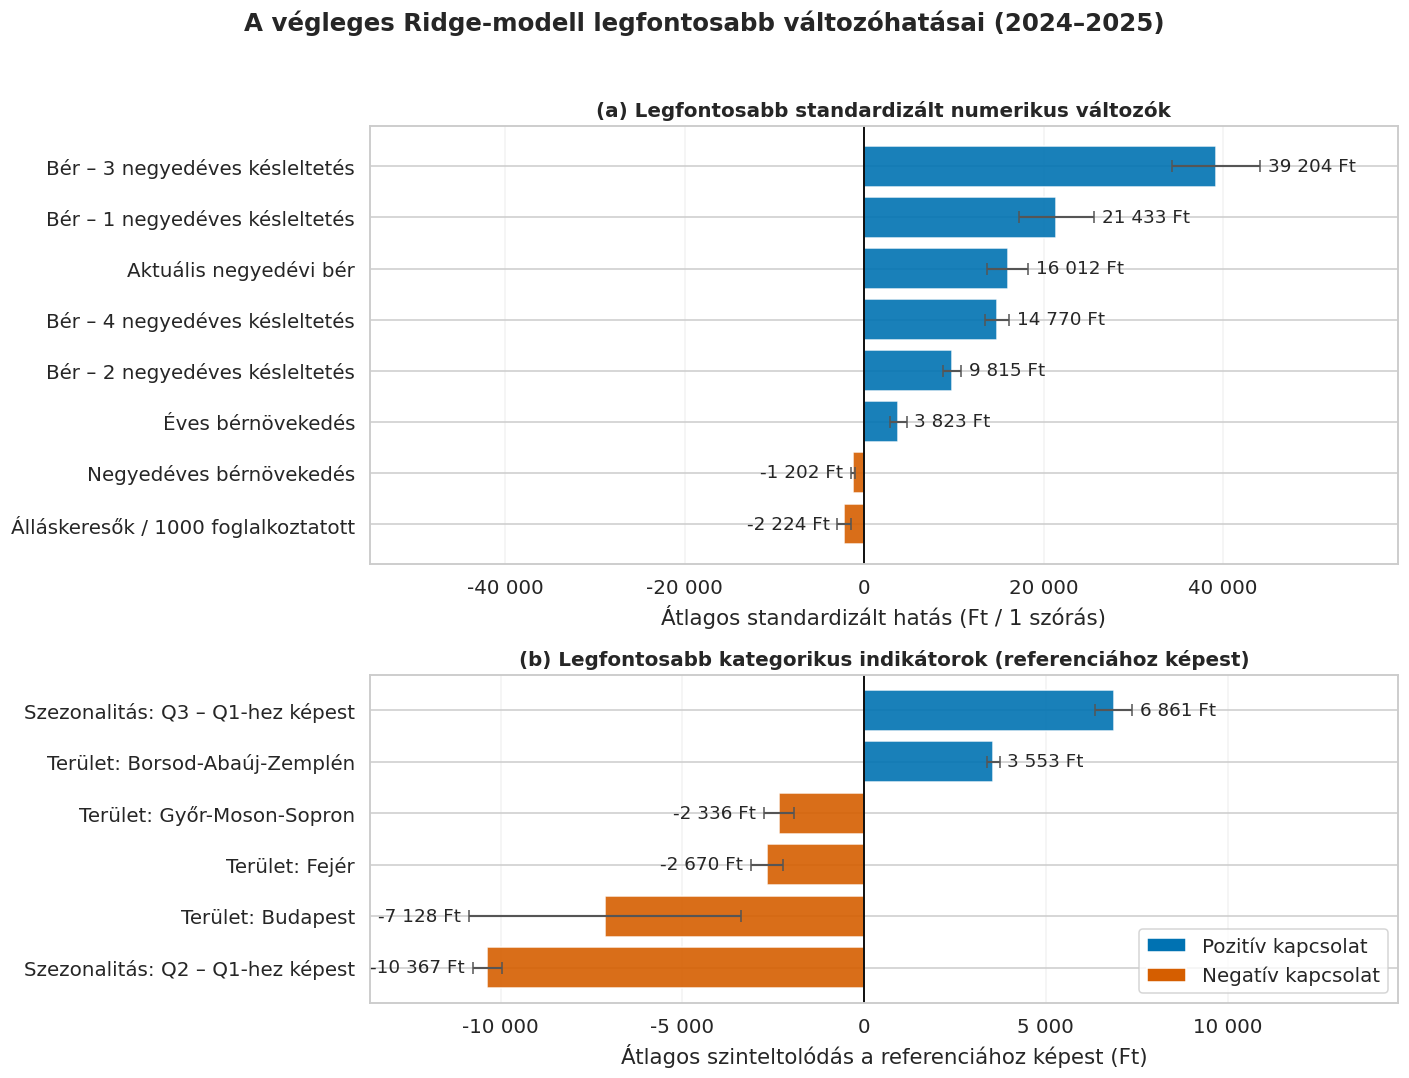

In [26]:
# --- 1. OSZLOPNEVEK AUTOMATIKUS FELISMERÉSE ---
# (Biztonsági lépés, ha esetleg más lenne az oszlopnév a CSV-dben)
mean_col = next((c for c in ["Átlagos_hatás", "Átlag", "Coef_mean", "Hatás_átlag", "Mean"] if c in coefficient_summary.columns), coefficient_summary.select_dtypes(include=[np.number]).columns[0])
std_col = next((c for c in ["Szórás", "Std", "Coef_std", "Hatás_szórás"] if c in coefficient_summary.columns), coefficient_summary.select_dtypes(include=[np.number]).columns[1])

df_coef = coefficient_summary.copy()

# --- 2. MAGYAR CÍMKÉK ÉS TÍPUSOK (NUMERIKUS VS. KATEGORIKUS) ---
# Ha még nincs külön oszlopod a szép magyar nevekre vagy a típusra, itt biztosítjuk:
label_col = "Megjelenített_név" if "Megjelenített_név" in df_coef.columns else "Feature"
clean_names = {
    "Bér_Lag3": "Bér – 3 negyedéves késleltetés",
    "Bér_Lag1": "Bér – 1 negyedéves késleltetés",
    "Bruttó_átlagkereset_HUF": "Aktuális negyedévi bér",
    "Bér_Lag4": "Bér – 4 negyedéves késleltetés",
    "Bér_Lag2": "Bér – 2 negyedéves késleltetés",
    "Bér_Növekedés_YoY": "Éves bérnövekedés",
    "Bér_Növekedés_QoQ": "Negyedéves bérnövekedés",
    "Álláskeresők_1000_foglalkoztatottra": "Álláskeresők / 1000 foglalkoztatott",
    "Negyedév_kategória_Q3": "Szezonalitás: Q3 – Q1-hez képest",
    "Negyedév_kategória_Q2": "Szezonalitás: Q2 – Q1-hez képest",
    "Munkanélküliségi_ráta_%": "Aktuális munkanélküliségi ráta",
    "Munkanélküliség_Delta": "Munkanélküliségi ráta változása",
    "Munkanélküliség_Lag1": "Munkanélküliség – 1 negyedéves késleltetés",
    "Munkanélküliség_Lag4": "Munkanélküliség – 4 negyedéves késleltetés",
    "Területi egység neve_Borsod-Abaúj-Zemplén": "Terület: Borsod-Abaúj-Zemplén",
    "Területi egység neve_Győr-Moson-Sopron": "Terület: Győr-Moson-Sopron",
    "Területi egység neve_Fejér": "Terület: Fejér",
    "Területi egység neve_Budapest": "Terület: Budapest"
}
df_coef[label_col] = df_coef[label_col].replace(clean_names)

# Kategorikus változók kiszűrése (Szezonalitás / Negyedév és Terület / Vármegye)
is_categorical = (
    df_coef[label_col].astype(str).str.contains("Szezonalitás:|Terület:|Negyedév_kategória|Területi egység|cat__", case=False, regex=True) |
    df_coef["Feature"].astype(str).str.contains("Negyedév_kategória|Területi egység|cat__", case=False, regex=True)
)

df_coef["Abs_hatás"] = df_coef[mean_col].abs()

# Szétválasztjuk a két csoportot:
# - Numerikus: a 8 legnagyobb abszolút hatású változó
# - Kategorikus: a 6 legnagyobb abszolút hatású indikátor (pl. Q2, Q3, Budapest stb.)
num_features = df_coef[~is_categorical].nlargest(8, "Abs_hatás").sort_values(mean_col, ascending=True)
cat_features = df_coef[is_categorical].nlargest(6, "Abs_hatás").sort_values(mean_col, ascending=True)

# --- 3. KÉTPANELES ÁBRA KIRAJZOLÁSA ---
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(13, 10),
    gridspec_kw={"height_ratios": [len(num_features), len(cat_features)]}
)

POS_COLOR = "#0072B2"  # Pozitív kapcsolat (kék)
NEG_COLOR = "#D55E00"  # Negatív kapcsolat (narancs/vörös)

panels = [
    (axes[0], num_features, "(a) Legfontosabb standardizált numerikus változók", "Átlagos standardizált hatás (Ft / 1 szórás)"),
    (axes[1], cat_features, "(b) Legfontosabb kategorikus indikátorok (referenciához képest)", "Átlagos szinteltolódás a referenciához képest (Ft)")
]

for ax, data, title, xlabel in panels:
    colors = [POS_COLOR if val >= 0 else NEG_COLOR for val in data[mean_col]]
    
    bars = ax.barh(
        data[label_col],
        data[mean_col],
        xerr=data[std_col],
        color=colors,
        alpha=0.9,
        edgecolor="white",
        error_kw={"ecolor": "#555555", "elinewidth": 1.4, "capsize": 4}
    )
    
    ax.axvline(0, color="black", linewidth=1.2)
    
    # Értékek kiírása az oszlopok mellé
    max_span = (data[mean_col].abs() + data[std_col]).max()
    ax.set_xlim(-max_span * 1.25, max_span * 1.35)
    
    for bar, mean_val, std_val in zip(bars, data[mean_col], data[std_col]):
        offset = (std_val + max_span * 0.02) if mean_val >= 0 else -(std_val + max_span * 0.02)
        ha_align = "left" if mean_val >= 0 else "right"
        
        ax.text(
            mean_val + offset,
            bar.get_y() + bar.get_height() / 2,
            f"{mean_val:,.0f} Ft".replace(",", " "),
            va="center",
            ha=ha_align,
            fontsize=12
        )
        
    ax.xaxis.set_major_formatter(huf_formatter)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.25)



# Közös jelmagyarázat (Legend)
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=POS_COLOR, label="Pozitív kapcsolat"),
    Patch(facecolor=NEG_COLOR, label="Negatív kapcsolat")
]
axes[1].legend(handles=legend_elements, loc="lower right", frameon=True)


fig.suptitle(
    "A végleges Ridge-modell legfontosabb változóhatásai (2024–2025)",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

# Mentés
fig.savefig(
    VIS_FIGURES / "04_17_ridge_feature_hatasok_ketpaneles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4.9. A notebook záró ellenőrzése

A záró audit ellenőrzi az eredménytáblák teljességét, a fontosabb
módszertani következtetéseket, valamint a vizualizációk és
exportált fájlok rendelkezésre állását.

In [27]:
# ALAPVETŐ ADATMÉRETEK

assert len(final_predictions) == 480
assert len(ridge_error_data) == 160
assert len(regional_errors) == 20
assert len(cluster_error_summary) == 2
assert len(quarterly_cluster_errors) == 16
assert len(wage_error_analysis) == 20
assert len(top_feature_effects) == 12

# MODELLTELJESÍTMÉNY

assert (
    final_ridge_result[
        "Átlag_MAE"
    ]
    <
    previous_naive_result[
        "Átlag_MAE"
    ]
)

assert (
    final_ridge_result[
        "Átlag_MAE"
    ]
    <
    seasonal_naive_result[
        "Átlag_MAE"
    ]
)

# KLASZTEREREDMÉNYEK

assert cluster_1_mae > cluster_2_mae
assert cluster_mae_difference_pct > 0

assert (
    worst_quarter_by_cluster[
        "Célnegyedév"
    ]
    .eq("2025Q1")
    .all()
)

assert (
    critical_quarter[
        "Felülbecslések_aránya_pct"
    ]
    .eq(100)
    .all()
)

# KORRELÁCIÓS KÖVETKEZTETÉSEK

assert mae_correlation[
    "Pearson_p"
] < 0.05

assert mape_correlation[
    "Pearson_p"
] >= 0.05

# FEATURE-HATÁSOK

assert top_feature[
    "Feature"
] == "Bér_Lag3"

assert top_feature_effects[
    "Foldok"
].eq(8).all()

# ÁBRÁK ÉS KIMENETEK

assert len(figure_manifest) == 5

assert figure_manifest[
    "PNG_létezik"
].all()

assert figure_manifest[
    "PDF_létezik"
].all()

notebook_4_audit = pd.DataFrame(
    [
        {
            "Ellenőrzés":
                "Mindhárom modell végső előrejelzése elérhető",
            "Eredmény": "Megfelelt"
        },

        {
            "Ellenőrzés":
                "A Ridge mindkét benchmarknál pontosabb",
            "Eredmény": "Megfelelt"
        },

        {
            "Ellenőrzés":
                "A klaszterenkénti hibák teljesek",
            "Eredmény": "Megfelelt"
        },

        {
            "Ellenőrzés":
                "A bérszint–hiba korrelációk elkészültek",
            "Eredmény": "Megfelelt"
        },

        {
            "Ellenőrzés":
                "A feature-hatások nyolc foldon alapulnak",
            "Eredmény": "Megfelelt"
        },

        {
            "Ellenőrzés":
                "Mind az öt végleges ábra rendelkezésre áll",
            "Eredmény": "Megfelelt"
        }
    ]
)

display(notebook_4_audit)

notebook_4_audit.to_csv(
    VIS_RESULTS
    / "KSH_notebook_4_zaro_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

print("=" * 80)
print(
    "A 4. notebook minden ellenőrzést "
    "teljesített és lezárható."
)
print("=" * 80)

,Ellenőrzés,Eredmény
0,Mindhárom modell végső előrejelzése elérhető,Megfelelt
1,A Ridge mindkét benchmarknál pontosabb,Megfelelt
2,A klaszterenkénti hibák teljesek,Megfelelt
3,A bérszint–hiba korrelációk elkészültek,Megfelelt
4,A feature-hatások nyolc foldon alapulnak,Megfelelt
5,Mind az öt végleges ábra rendelkezésre áll,Megfelelt


A 4. notebook minden ellenőrzést teljesített és lezárható.
